In [2]:
import pandas as pd
import geopandas as gpd
from pathlib import Path

In [2]:
print(Path.cwd())

C:\Users\hp\OneDrive - University of Bristol\Dissertation\Pycharm_Projects


In [3]:
# Read all the necessary data

In [4]:
crime_sw_path = Path("Data/Crime_data/South_West_England/crime_filtered_sw.gpkg")
poi_sw_path = Path("Data/POI/South_West_England/poi_sw.gpkg")
intersections_sw_path = Path("Data/MRN_intersections/South_West_England/intersections_sw.gpkg")
spatial_signatures_sw_path = Path("JupyterProject/spatial_signatures(land_use)/spatial_signatures_sw.gpkg")

In [5]:
df_crime_sw = gpd.read_file(crime_sw_path, engine="pyogrio")
df_poi_sw = gpd.read_file(poi_sw_path, engine="pyogrio")
df_intersections_sw = gpd.read_file(intersections_sw_path, engine="pyogrio")
df_spatial_signature_sw = gpd.read_file(spatial_signatures_sw_path, engine="pyogrio")

In [6]:
df_crime_sw.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1461051 entries, 0 to 1461050
Data columns (total 15 columns):
 #   Column                 Non-Null Count    Dtype   
---  ------                 --------------    -----   
 0   Crime ID               1203183 non-null  str     
 1   Month                  1461051 non-null  str     
 2   Reported by            1461051 non-null  str     
 3   Falls within           1461051 non-null  str     
 4   Longitude              1461051 non-null  float64 
 5   Latitude               1461051 non-null  float64 
 6   Location               1461051 non-null  str     
 7   LSOA code              1461051 non-null  str     
 8   LSOA name              1461051 non-null  str     
 9   Crime type             1461051 non-null  str     
 10  Last outcome category  1203183 non-null  str     
 11  Context                0 non-null        float64 
 12  source_month           1461051 non-null  str     
 13  source_file            1461051 non-null  str     

In [7]:
df_poi_sw.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 391264 entries, 0 to 391263
Data columns (total 31 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   ref_no             391264 non-null  int64         
 1   name               391264 non-null  str           
 2   pointx_class       391264 non-null  str           
 3   groupname          391264 non-null  str           
 4   categoryname       391264 non-null  str           
 5   classname          391264 non-null  str           
 6   feature_easting    391264 non-null  float64       
 7   feature_northing   391264 non-null  float64       
 8   pos_accuracy       391264 non-null  int64         
 9   uprn               175062 non-null  float64       
 10  topo_toid          391264 non-null  str           
 11  topo_toid_version  391264 non-null  int64         
 12  usrn               391264 non-null  str           
 13  usrn_mi            391264 non-null  

In [8]:
df_intersections_sw.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 306291 entries, 0 to 306290
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype   
---  ------             --------------   -----   
 0   os_parentid_x      306291 non-null  str     
 1   startnode-endnode  306291 non-null  str     
 2   degree             306291 non-null  int64   
 3   os_parentid_y      306291 non-null  str     
 4   nodeid             306291 non-null  float64 
 5   geometry           306291 non-null  geometry
dtypes: float64(1), geometry(1), int64(1), str(3)
memory usage: 45.6 MB


In [9]:
df_spatial_signature_sw.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 9216 entries, 0 to 9215
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id        9216 non-null   str     
 1   code      9216 non-null   str     
 2   type      9216 non-null   str     
 3   geometry  9216 non-null   geometry
dtypes: geometry(1), str(3)
memory usage: 561.2 KB


In [10]:
df_spatial_signature_sw['type'].value_counts()

type
Open sprawl                             1622
Urban buffer                            1254
Wild countryside                        1227
Countryside agriculture                 1113
Disconnected suburbia                   1109
Accessible suburbia                      777
Warehouse/Park land                      669
Dense residential neighbourhoods         482
Gridded residential quarters             296
Connected residential neighbourhoods     253
Dense urban neighbourhoods               233
Local urbanity                           145
Regional urbanity                         22
Metropolitan urbanity                     12
outlier                                    2
Name: count, dtype: int64

In [11]:
sw_path = Path("JupyterProject/south_west_boundary.geojson")
sw_bound = gpd.read_file(sw_path)

In [12]:
sw_bound

,FID,RGN25CD,RGN25NM,RGN25NMW,BNG_E,BNG_N,LONG,LAT,GlobalID,geometry
0,9,E12000009,South West,De Orllewin,285016,102566,-3.633425,50.81119,dd3d5d0f-6fda-4a68-bb9a-fd302fb7ce01,"MULTIPOLYGON (((-6.39952 49.86527, -6.39941 49..."


In [13]:
# Using the official look up data between Lower Super Output Areas (LSOA), Built-up Areas (BUA), Local Authority Districts (LAD), and regions,
# We can filter the LSOAs so it will only consist LSOA in south west region

In [14]:
# Read LSOA lookup files

In [15]:
lsoa_lookup_path = Path("Data/LSOA_boundaries_2021/LSOA_(2021)_to_Built_Up_Area_to_Local_Authority_District_to_Region_(December_2022)_Lookup_in_England_and_Wales_v2.geojson")
lsoa_lookup = gpd.read_file(lsoa_lookup_path, engine="pyogrio")

In [16]:
lsoa_sw_list = lsoa_lookup[lsoa_lookup['RGN22CD'] == 'E12000009']
lsoa_sw_list.LSOA21CD.nunique()

3407

In [17]:
lsoa_sw_list

,LSOA21CD,LSOA21NM,LSOA21NMW,BUA22CD,BUA22NM,BUA22NMW,LAD22CD,LAD22NM,LAD22NMW,RGN22CD,RGN22NM,RGN22NMW,ObjectId,geometry
13600,E01014531,Bristol 035D,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13601,None
13601,E01014532,Bristol 035E,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13602,None
13602,E01014533,Bristol 043A,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13603,None
13603,E01014534,Bristol 043B,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13604,None
13604,E01014535,Bristol 043C,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13605,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33238,E01035229,South Gloucestershire 035C,NaN,E63004949,Stoke Gifford,NaN,E06000025,South Gloucestershire,NaN,E12000009,South West,NaN,33239,None
33239,E01035230,South Gloucestershire 035D,NaN,E63005057,Bristol,NaN,E06000025,South Gloucestershire,NaN,E12000009,South West,NaN,33240,None
33240,E01035231,South Gloucestershire 035E,NaN,E63004949,Stoke Gifford,NaN,E06000025,South Gloucestershire,NaN,E12000009,South West,NaN,33241,None
33241,E01035232,South Gloucestershire 036B,NaN,E63004949,Stoke Gifford,NaN,E06000025,South Gloucestershire,NaN,E12000009,South West,NaN,33242,None


In [18]:
# Clip or overlay the LSOA according to the LSOA South West list

In [19]:
lsoa_path = Path("Data/LSOA_boundaries_2021/Lower_layer_Super_Output_Areas_December_2021_Boundaries_EW_BFC_V10_-672099234420024429.gpkg")
df_lsoa = gpd.read_file(lsoa_path, engine='pyogrio')

In [20]:
df_lsoa.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 35672 entries, 0 to 35671
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   LSOA21CD   35672 non-null  str     
 1   LSOA21NM   35672 non-null  str     
 2   LSOA21NMW  35672 non-null  str     
 3   BNG_E      35672 non-null  int32   
 4   BNG_N      35672 non-null  int32   
 5   LAT        35672 non-null  float32 
 6   LONG       35672 non-null  float32 
 7   GlobalID   35672 non-null  str     
 8   geometry   35672 non-null  geometry
dtypes: float32(2), geometry(1), int32(2), str(4)
memory usage: 4.1 MB


In [21]:
df_lsoa.head()

,LSOA21CD,LSOA21NM,LSOA21NMW,BNG_E,BNG_N,LAT,LONG,GlobalID,geometry
0,E01000001,City of London 001A,,532123,181632,51.518169,-0.097150,{C625AEA8-6D73-4B2A-BE76-4D5C44CAD9F8},"MULTIPOLYGON (((532151.537 181867.433, 532149...."
1,E01000002,City of London 001B,,532480,181715,51.518829,-0.091970,{52C878E9-AC68-4886-B4A8-FEA9CD241A70},"MULTIPOLYGON (((532634.497 181926.016, 532632...."
2,E01000003,City of London 001C,,532239,182033,51.521740,-0.095330,{B9D8FACA-D489-478D-8CE6-ACAF76186D7D},"MULTIPOLYGON (((532153.703 182165.155, 532149...."
3,E01000005,City of London 001E,,533581,181283,51.514690,-0.076280,{15E1417D-537C-4845-9820-FC7596BD59B0},"MULTIPOLYGON (((533619.062 181402.364, 533615...."
4,E01000006,Barking and Dagenham 016A,,544994,184274,51.538750,0.089317,{8A6C4EE0-C0FF-4736-9CFA-FB12A6D50DA0},"MULTIPOLYGON (((545126.852 184310.838, 545125...."


In [22]:
# Check for duplicates both

In [23]:
print("Geometry duplicates:",
      df_lsoa["LSOA21CD"].duplicated().sum())

print("Lookup duplicates:",
      lsoa_sw_list["LSOA21CD"].duplicated().sum())

Geometry duplicates: 0
Lookup duplicates: 0


In [24]:
# Clean the code columns
df_lsoa["LSOA21CD"] = df_lsoa["LSOA21CD"].astype("string").str.strip()
lsoa_sw_list["LSOA21CD"] = (
    lsoa_sw_list["LSOA21CD"]
    .astype("string")
    .str.strip()
)

# Keep only official South West LSOAs
lsoa_sw = df_lsoa[
    df_lsoa["LSOA21CD"].isin(lsoa_sw_list["LSOA21CD"])
].copy()

print("Official South West LSOAs:", lsoa_sw["LSOA21CD"].nunique())
print("Rows:", len(lsoa_sw))
print("CRS:", lsoa_sw.crs)

Official South West LSOAs: 3407
Rows: 3407
CRS: EPSG:27700


In [25]:
lsoa_sw.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 3407 entries, 13647 to 33227
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   LSOA21CD   3407 non-null   string  
 1   LSOA21NM   3407 non-null   str     
 2   LSOA21NMW  3407 non-null   str     
 3   BNG_E      3407 non-null   int32   
 4   BNG_N      3407 non-null   int32   
 5   LAT        3407 non-null   float32 
 6   LONG       3407 non-null   float32 
 7   GlobalID   3407 non-null   str     
 8   geometry   3407 non-null   geometry
dtypes: float32(2), geometry(1), int32(2), str(3), string(1)
memory usage: 431.8 KB


In [26]:
lsoa_sw.crs

<Projected CRS: EPSG:27700>
Name: OSGB36 / British National Grid
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: United Kingdom (UK) - offshore to boundary of UKCS within 49°45'N to 61°N and 9°W to 2°E; onshore Great Britain (England, Wales and Scotland). Isle of Man onshore.
- bounds: (-9.01, 49.75, 2.01, 61.01)
Coordinate Operation:
- name: British National Grid
- method: Transverse Mercator
Datum: Ordnance Survey of Great Britain 1936
- Ellipsoid: Airy 1830
- Prime Meridian: Greenwich

In [27]:
# Check empty geometries of filtered LSOA within south west region

In [28]:
lsoa_sw[lsoa_sw.geometry.is_empty == True] # Check if there's row with empty geometry

,LSOA21CD,LSOA21NM,LSOA21NMW,BNG_E,BNG_N,LAT,LONG,GlobalID,geometry


In [29]:
lsoa_density = lsoa_sw.copy()

In [30]:
lsoa_density['area_km2'] = lsoa_density.geometry.area / 1_000_000

In [31]:
lsoa_density

,LSOA21CD,LSOA21NM,LSOA21NMW,BNG_E,BNG_N,LAT,LONG,GlobalID,geometry,area_km2
13647,E01014370,Bath and North East Somerset 007A,,375084,164994,51.383438,-2.35942,{4803A59D-E95B-4FE6-BEB0-E69E84BD7D48},"MULTIPOLYGON (((375292.289 165633.714, 375288....",0.377030
13648,E01014371,Bath and North East Somerset 007B,,375328,164841,51.382069,-2.35590,{9C5F2B67-06C6-477C-83FF-A8DEFC8C184F},"MULTIPOLYGON (((375624.781 165202.406, 375619....",0.409491
13649,E01014372,Bath and North East Somerset 007C,,374832,165378,51.386879,-2.36307,{34817845-639D-4BDC-85F2-3650D6948257},"MULTIPOLYGON (((375327.102 165666.338, 375313....",0.166801
13650,E01014373,Bath and North East Somerset 010A,,377791,167691,51.407799,-2.32069,{CF46DDA7-D5D4-4F32-883D-D6813023538C},"MULTIPOLYGON (((377762.251 168340.474, 377738....",1.059979
13651,E01014374,Bath and North East Somerset 010B,,378059,166769,51.399521,-2.31678,{9B5DFE41-266E-4AB9-813E-8592E3AC4BB0},"MULTIPOLYGON (((378818.843 167715.55, 378817.4...",5.002127
...,...,...,...,...,...,...,...,...,...,...
33223,E01035229,South Gloucestershire 035C,,361662,178206,51.501480,-2.55372,{FFCFBCDA-4686-4F28-BCB2-87F483316D15},"MULTIPOLYGON (((362036.795 178559.778, 362035....",0.580155
33224,E01035230,South Gloucestershire 035D,,361216,178172,51.501141,-2.56014,{75AF98C1-D8D9-4FA8-8123-12C67DF32C60},"MULTIPOLYGON (((361548.098 178707.611, 361546 ...",0.632230
33225,E01035231,South Gloucestershire 035E,,361945,177516,51.495300,-2.54956,{FFE85EA9-855F-4746-B64D-7DA442E1FEAB},"MULTIPOLYGON (((361922.063 177801.938, 361918....",0.440986
33226,E01035232,South Gloucestershire 036B,,362900,179544,51.513592,-2.53602,{17EEB482-0456-4254-926A-BCA01EA1C8E3},"MULTIPOLYGON (((363286 179964, 363286 179978, ...",0.652123


In [32]:
lsoa_density2 = lsoa_density.copy()

In [33]:
# Assign LSOA to POI

In [34]:
df_poi_sw.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [35]:
# Convert the POI CRS to LSOA CRS

In [36]:
df_poi_sw = df_poi_sw.to_crs(lsoa_sw.crs)

In [37]:
poi_sw_lsoa = gpd.sjoin(
    df_poi_sw,
    lsoa_sw[["LSOA21CD", "LSOA21NM", "geometry"]],
    how="left",
    predicate="within"
)

In [38]:
poi_sw_lsoa

,ref_no,name,pointx_class,groupname,categoryname,classname,feature_easting,feature_northing,pos_accuracy,uprn,...,qualifier_type,qualifier_data,provenance,supply_date,source_file,source_folder,geometry,index_right,LSOA21CD,LSOA21NM
0,166806215,Carrs Volkswagen Van Centre Indian Queens,09490695,Retail,Motoring,New Vehicles,192388.0,59304.0,1,1.003463e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (192388.001 59303.999),18079.0,E01019063,Cornwall 019D
1,166806217,Carrs Select Scorrier,09490695,Retail,Motoring,New Vehicles,172473.0,44630.0,1,NaN,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (172473.001 44629.999),17846.0,E01018820,Cornwall 047D
2,166806224,Vertu Volvo Truro,09490695,Retail,Motoring,New Vehicles,177715.0,45002.0,1,1.000410e+11,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (177715.001 45001.999),17845.0,E01018819,Cornwall 043A
3,166806225,Carrs Land Rover,09490695,Retail,Motoring,New Vehicles,172552.0,44706.0,1,1.000121e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (172552.001 44705.999),17846.0,E01018820,Cornwall 047D
4,181524408,Exeter Van Store,09490695,Retail,Motoring,New Vehicles,291945.6,90995.5,1,1.001304e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (291945.601 90995.499),18949.0,E01019969,Exeter 014B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
391259,170996524,Unique Cleaning Group,02070100,Commercial Services,Contract Services,Contract Cleaning Services,394673.5,222729.5,1,1.001214e+11,...,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (394673.501 222729.5),21041.0,E01022153,Cheltenham 004D
391260,64371470,Margaret Reid Display Solutions,02070101,Commercial Services,Contract Services,Display and Window Dressers,384301.0,201139.0,1,1.001214e+11,...,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (384301.001 201139),21228.0,E01022350,Stroud 010A
391261,104573666,Daktronics,02070101,Commercial Services,Contract Services,Display and Window Dressers,381424.0,212678.0,1,1.000731e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (381424.001 212678),32835.0,E01034797,Gloucester 015K
391262,161943034,Vod Visual,02070101,Commercial Services,Contract Services,Display and Window Dressers,411315.0,183056.3,1,1.009004e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (411315.001 183056.299),14718.0,E01015501,Swindon 022A


In [39]:
poi_sw_lsoa.groupname.unique()

<ArrowStringArray>
[                            'Retail',                          'Transport',
       'Manufacturing and Production',                'Commercial Services',
 'Accommodation, Eating and Drinking',                        'Attractions',
            'Sport and Entertainment',              'Public Infrastructure',
               'Education and Health']
Length: 9, dtype: str

In [40]:
poi_sw_lsoa.categoryname.unique()

<ArrowStringArray>
[                                     'Motoring',
                                 'Road and Rail',
                      'Clothing and Accessories',
                                       'Farming',
                           'Legal and Financial',
 'It, Advertising, Marketing and Media Services',
         'Personal, Consumer and Other Services',
                                           'Air',
                                 'Hire Services',
                                 'Accommodation',
                           'Eating and Drinking',
                         'Construction Services',
                             'Consumer Products',
                         'Extractive Industries',
             'Property and Development Services',
                            'Recycling Services',
                          'Repair and Servicing',
                           'Research and Design',
               'Transport, Storage and Delivery',
                      'Botanica

In [41]:
poi_sw_lsoa.LSOA21CD.nunique()

3406

In [42]:
# check how many POI did not match with LSOA

# Previously all the datasets have been checked; whether there are rows with duplicated or null values,
# or whether there are rows with empty geometries, it's all been filtered.

In [43]:
print(
    "POI unmatched:",
    poi_sw_lsoa["LSOA21CD"].isna().sum()
)

POI unmatched: 75


In [44]:
# There are 75 rows of POI that don't have LSOA data

In [45]:
# Checking whether the POI and LSOA have different CRS

In [46]:
print("LSOA CRS:", lsoa_sw.crs)
print("POI CRS:", df_poi_sw.crs)
#print("Intersections CRS:", df_intersections_sw.crs)

LSOA CRS: EPSG:27700
POI CRS: EPSG:27700


In [47]:
# All the necessary datasets have the same CRS

In [48]:
# There are 75 out of 391,264 points (0.002%) that have empty LSOA. It's okay to drop the empty LSOA.

In [49]:
poi_unmatched = poi_sw_lsoa[
    poi_sw_lsoa["LSOA21CD"].isna()
].copy()

# Entire POIs

print(f'Entire POIs: {len(df_poi_sw)}')

print(
    "POI unmatched:",
    poi_sw_lsoa["LSOA21CD"].isna().sum(),
    f"({poi_sw_lsoa['LSOA21CD'].isna().mean():.2%})"
)

Entire POIs: 391264
POI unmatched: 75 (0.02%)


In [50]:
# Checking whether one of the POIs is out of boundaries

In [51]:
print("LSOA bounds:", lsoa_sw.total_bounds)
print("All POI bounds:", df_poi_sw.total_bounds)
print("Unmatched POI bounds:", poi_unmatched.total_bounds)

LSOA bounds: [ 82668.52    5336.966 435913.5   246053.797]
All POI bounds: [131973.00057198  11456.99931871 434999.60082217 244967.99954251]
Unmatched POI bounds: [151426.00058927  17834.99932293 422072.00080175 234736.99953109]


In [52]:
# Checking if there are invalid, missing, or empty geometries

In [53]:
print("Missing geometry:", poi_unmatched.geometry.isna().sum())
print("Empty geometry:", poi_unmatched.geometry.is_empty.sum())
print("Invalid geometry:", (~poi_unmatched.geometry.is_valid).sum())

Missing geometry: 0
Empty geometry: 0
Invalid geometry: 0


In [54]:
# Trying to see whether these unmatched POIs belong to the same group

In [55]:
print(
    poi_unmatched["groupname"]
    .value_counts()
    .head(30)
)

groupname
Transport                       64
Attractions                      6
Public Infrastructure            3
Sport and Entertainment          1
Manufacturing and Production     1
Name: count, dtype: int64


In [56]:
# Look into the distributions of unmatched POI geographically

<Axes: >

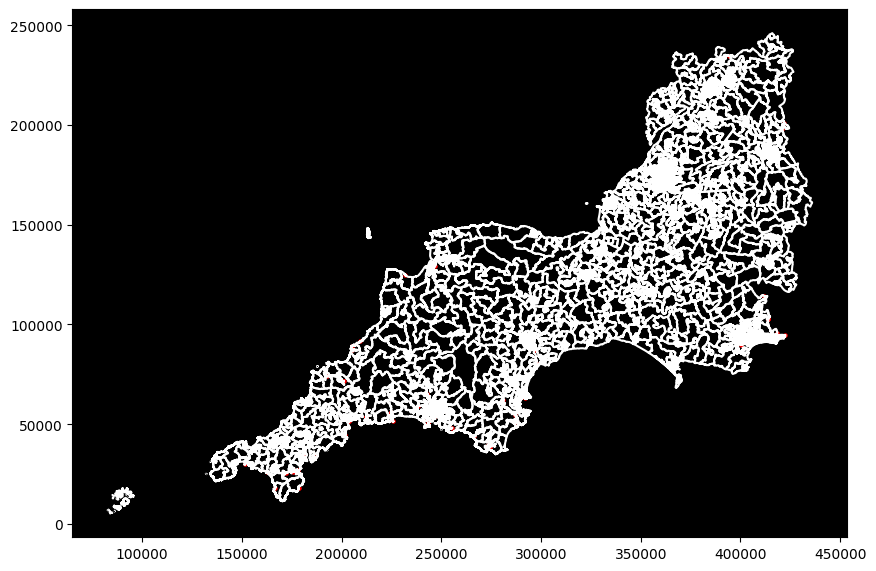

In [57]:
ax = lsoa_sw.boundary.plot(figsize=(10,10), color="white")

ax.set_facecolor('black')

poi_unmatched.plot(
    ax=ax,
    color="red",
    markersize=5
)

In [58]:
# After some check, the LSOA data type that was downloaded is BFC version, which is the most detailed resolution
# While the POI data resolution is much detailed than the LSOA data (1-5 m)
# So these unmatched POI occurred because the resolution disparity between the LSOA and POI, and also intersections
# But since the unmatched POIs are around 0.02% of the whole dataset, it's not impacting the dataset significantly.
# So we can drop these unmatched POIs.

In [59]:
poi_sw_lsoa = poi_sw_lsoa.dropna(subset=["LSOA21CD"]).copy()

In [60]:
poi_sw_lsoa.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 391189 entries, 0 to 391263
Data columns (total 34 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   ref_no             391189 non-null  int64         
 1   name               391189 non-null  str           
 2   pointx_class       391189 non-null  str           
 3   groupname          391189 non-null  str           
 4   categoryname       391189 non-null  str           
 5   classname          391189 non-null  str           
 6   feature_easting    391189 non-null  float64       
 7   feature_northing   391189 non-null  float64       
 8   pos_accuracy       391189 non-null  int64         
 9   uprn               175062 non-null  float64       
 10  topo_toid          391189 non-null  str           
 11  topo_toid_version  391189 non-null  int64         
 12  usrn               391189 non-null  str           
 13  usrn_mi            391189 non-null  int64

In [61]:
poi_sw_lsoa.LSOA21CD.nunique()

3406

In [62]:
poi_sw_lsoa.geographic_county.unique()

<ArrowStringArray>
[       'Cornwall',           'Devon',        'Somerset',          'Dorset',
       'Wiltshire',         'Bristol', 'Gloucestershire']
Length: 7, dtype: str

In [63]:
poi_sw_lsoa.groupname.unique()

<ArrowStringArray>
[                            'Retail',                          'Transport',
       'Manufacturing and Production',                'Commercial Services',
 'Accommodation, Eating and Drinking',                        'Attractions',
            'Sport and Entertainment',              'Public Infrastructure',
               'Education and Health']
Length: 9, dtype: str

In [64]:
# Intersection Density

In [65]:
# Assign LSOA to Intersection Density

In [66]:
df_intersections_sw = df_intersections_sw.to_crs(lsoa_sw.crs)

In [67]:
intersections_sw_lsoa = gpd.sjoin(
    df_intersections_sw,
    lsoa_sw[["LSOA21CD", "LSOA21NM", "geometry"]],
    how="left",
    predicate="within"
).drop(["index_right"], axis=1)

In [68]:
intersections_sw_lsoa.head()

,os_parentid_x,startnode-endnode,degree,os_parentid_y,nodeid,geometry,LSOA21CD,LSOA21NM
0,63a220f4-79d0-4ec0-89fa-8e95174e6d74,3e3bdba7-e915-4866-bd52-b7c724ae89b1,8,3e3bdba7-e915-4866-bd52-b7c724ae89b1,501850474.0,POINT (164140.756 39802.839),E01018877,Cornwall 053D
1,7ebf0e72-bb87-4675-b186-279ec6ef6527,08a4aff9-5f8a-40b1-beb4-c4975526ea3b,8,08a4aff9-5f8a-40b1-beb4-c4975526ea3b,500256810.0,POINT (210980.113 52407.902),E01019025,Cornwall 035B
2,10e72d83-e99f-4ccb-809b-d44a76ab2fbf,89d9be91-dbd4-46f7-b831-9eedc327b592,8,89d9be91-dbd4-46f7-b831-9eedc327b592,504099891.0,POINT (405382.627 91559.715),E01015462,"Bournemouth, Christchurch and Poole 043D"
3,3b160890-3621-4f3b-b42f-eb7d57859d02,7a49aa9d-ee15-459e-81a3-7361c94ffae4,8,7a49aa9d-ee15-459e-81a3-7361c94ffae4,503636492.0,POINT (357015.576 173270.6),E01014544,Bristol 030A
4,c78bf5cf-bdad-453a-b02a-855fedbc7ba7,176f3a59-64d2-4f67-9c57-a9377d00960c,8,176f3a59-64d2-4f67-9c57-a9377d00960c,500696120.0,POINT (387924.202 215905.11),E01034809,Tewkesbury 009H


In [69]:
# Checking whether there are unmatched intersections

In [70]:
# Entire Intersections

print(f'Entire Intersections: {len(df_intersections_sw)}')

Entire Intersections: 306291


In [71]:
print(
    "Intersections unmatched:",
    intersections_sw_lsoa["LSOA21CD"].isna().sum(),
    f"({intersections_sw_lsoa['LSOA21CD'].isna().mean():.4%})"
)

Intersections unmatched: 8 (0.0026%)


In [72]:
# The unmatched intersection numbers are also not that significant, we can also drop this.

In [73]:
intersections_sw_lsoa = intersections_sw_lsoa.dropna(subset=["LSOA21CD"]).copy()

In [74]:
# Spatial Signature

In [75]:
# Split the spatial signature that was split per region into per LSOA in south west region

In [76]:
signatures_lsoa_split = gpd.overlay(
    df_spatial_signature_sw[["type", "geometry"]],
    lsoa_sw[["LSOA21CD", "LSOA21NM", "geometry"]],
    how="intersection",
    keep_geom_type=True
)

In [77]:
signatures_lsoa_split

,type,LSOA21CD,LSOA21NM,geometry
0,Urban buffer,E01020566,Dorset 048D,"POLYGON ((367883.52 69960.18, 367869.77 69970...."
1,Urban buffer,E01020566,Dorset 048D,"POLYGON ((367934.35 70147.854, 367941.159 7022..."
2,Urban buffer,E01020566,Dorset 048D,"POLYGON ((368122.591 70124.169, 368121.489 701..."
3,Urban buffer,E01020566,Dorset 048D,"POLYGON ((368163.934 70220.528, 368161.099 702..."
4,Urban buffer,E01033200,Dorset 047C,"POLYGON ((368088.05 74605.67, 368083.13 74599...."
...,...,...,...,...
19295,Open sprawl,E01022211,Cotswold 002D,"POLYGON ((420834.723 232796.831, 420835.54 232..."
19296,Open sprawl,E01034781,Cotswold 002F,"MULTIPOLYGON (((421182.376 232413.218, 421183...."
19297,Open sprawl,E01034782,Cotswold 002G,"MULTIPOLYGON (((421169 232460, 421171.245 2324..."
19298,Countryside agriculture,E01022211,Cotswold 002D,"POLYGON ((420423.099 232669.14, 420423.629 232..."


In [78]:
signatures_lsoa_split["signature_area_km2"] = signatures_lsoa_split.geometry.area/1_000

In [79]:
signatures_lsoa_split

,type,LSOA21CD,LSOA21NM,geometry,signature_area_km2
0,Urban buffer,E01020566,Dorset 048D,"POLYGON ((367883.52 69960.18, 367869.77 69970....",4.692073
1,Urban buffer,E01020566,Dorset 048D,"POLYGON ((367934.35 70147.854, 367941.159 7022...",9.067667
2,Urban buffer,E01020566,Dorset 048D,"POLYGON ((368122.591 70124.169, 368121.489 701...",1.973760
3,Urban buffer,E01020566,Dorset 048D,"POLYGON ((368163.934 70220.528, 368161.099 702...",0.388316
4,Urban buffer,E01033200,Dorset 047C,"POLYGON ((368088.05 74605.67, 368083.13 74599....",0.338680
...,...,...,...,...,...
19295,Open sprawl,E01022211,Cotswold 002D,"POLYGON ((420834.723 232796.831, 420835.54 232...",61.378616
19296,Open sprawl,E01034781,Cotswold 002F,"MULTIPOLYGON (((421182.376 232413.218, 421183....",82.502277
19297,Open sprawl,E01034782,Cotswold 002G,"MULTIPOLYGON (((421169 232460, 421171.245 2324...",15.634834
19298,Countryside agriculture,E01022211,Cotswold 002D,"POLYGON ((420423.099 232669.14, 420423.629 232...",1.190530


In [80]:
signatures_lsoa_split['type'].value_counts()

type
Open sprawl                             3955
Urban buffer                            3337
Countryside agriculture                 2404
Disconnected suburbia                   2187
Accessible suburbia                     1784
Wild countryside                        1442
Warehouse/Park land                     1168
Dense residential neighbourhoods         972
Gridded residential quarters             640
Connected residential neighbourhoods     530
Dense urban neighbourhoods               511
Local urbanity                           281
Regional urbanity                         67
Metropolitan urbanity                     20
outlier                                    2
Name: count, dtype: int64

In [81]:
signature_area = (
    signatures_lsoa_split
    .groupby("type", as_index=False)["signature_area_km2"]
    .sum()
    .sort_values("signature_area_km2", ascending=False)
)

print(signature_area)

                                    type  signature_area_km2
2                Countryside agriculture        1.720746e+07
11                          Urban buffer        2.825927e+06
13                      Wild countryside        2.798271e+06
9                            Open sprawl        4.303844e+05
0                    Accessible suburbia        1.476455e+05
5                  Disconnected suburbia        8.760365e+04
12                   Warehouse/Park land        8.418614e+04
3       Dense residential neighbourhoods        3.833131e+04
6           Gridded residential quarters        2.770052e+04
4             Dense urban neighbourhoods        2.201131e+04
1   Connected residential neighbourhoods        1.857845e+04
7                         Local urbanity        1.100493e+04
10                     Regional urbanity        4.794350e+03
8                  Metropolitan urbanity        1.882825e+02
14                               outlier        1.201408e+00


In [82]:
# Drop outlier since it does not explicitly represent land cover or land use and it's not big

In [83]:
signatures_lsoa_no_outlier = signatures_lsoa_split.copy()
signatures_lsoa_no_outlier = signatures_lsoa_no_outlier[(signatures_lsoa_no_outlier["type"]!= 'outlier')]

In [84]:
# chatgpt

signature_macro_map = {
    # Urban
    "Hyper concentrated urbanity": "Urban",
    "Concentrated urbanity": "Urban",
    "Metropolitan urbanity": "Urban",
    "Regional urbanity": "Urban",
    "Local urbanity": "Urban",
    "Dense urban neighbourhoods": "Urban",
    "Gridded residential quarters": "Urban",
    "Dense residential neighbourhoods": "Urban",

    # Suburban
    "Connected residential neighbourhoods": "Suburban",
    "Accessible suburbia": "Suburban",
    "Disconnected suburbia": "Suburban",
    "Open sprawl": "Suburban",
    "Urban buffer": "Suburban",
    "Warehouse/Park land": "Suburban",

    # Rural
    "Countryside agriculture": "Rural",
    "Wild countryside": "Rural"

}

In [85]:
# perplexity

signature_macro_map2 = {
    # Urban
    "Metropolitan urbanity": "Urban",
    "Regional urbanity": "Urban",
    "Local urbanity": "Urban",
    "Dense urban neighbourhoods": "Urban",
    "Gridded residential quarters": "Urban",
    "Connected residential neighbourhoods": "Urban",
    "Dense residential neighbourhoods": "Urban",

    # Suburban
    "Accessible suburbia": "Suburban",
    "Disconnected suburbia": "Suburban",
    "Open sprawl": "Suburban",
    "Warehouse/Park land": "Suburban",

    # Rural
    "Countryside agriculture": "Rural",
    "Wild countryside": "Rural",
    "Urban buffer": "Rural"

}

In [86]:
signatures_lsoa_no_outlier2 = signatures_lsoa_no_outlier.copy()

signatures_lsoa_no_outlier2["macro_group"] = (
    signatures_lsoa_no_outlier2["type"]
    .map(signature_macro_map2)
    .fillna("Other")
)

In [87]:
signatures_lsoa_no_outlier = signatures_lsoa_no_outlier.copy()

signatures_lsoa_no_outlier["macro_group"] = (
    signatures_lsoa_no_outlier["type"]
    .map(signature_macro_map)
    .fillna("Other")
)

In [88]:
signatures_lsoa_no_outlier2

,type,LSOA21CD,LSOA21NM,geometry,signature_area_km2,macro_group
0,Urban buffer,E01020566,Dorset 048D,"POLYGON ((367883.52 69960.18, 367869.77 69970....",4.692073,Rural
1,Urban buffer,E01020566,Dorset 048D,"POLYGON ((367934.35 70147.854, 367941.159 7022...",9.067667,Rural
2,Urban buffer,E01020566,Dorset 048D,"POLYGON ((368122.591 70124.169, 368121.489 701...",1.973760,Rural
3,Urban buffer,E01020566,Dorset 048D,"POLYGON ((368163.934 70220.528, 368161.099 702...",0.388316,Rural
4,Urban buffer,E01033200,Dorset 047C,"POLYGON ((368088.05 74605.67, 368083.13 74599....",0.338680,Rural
...,...,...,...,...,...,...
19295,Open sprawl,E01022211,Cotswold 002D,"POLYGON ((420834.723 232796.831, 420835.54 232...",61.378616,Suburban
19296,Open sprawl,E01034781,Cotswold 002F,"MULTIPOLYGON (((421182.376 232413.218, 421183....",82.502277,Suburban
19297,Open sprawl,E01034782,Cotswold 002G,"MULTIPOLYGON (((421169 232460, 421171.245 2324...",15.634834,Suburban
19298,Countryside agriculture,E01022211,Cotswold 002D,"POLYGON ((420423.099 232669.14, 420423.629 232...",1.190530,Rural


In [89]:
# Crime Data Handling

In [90]:
df_crime_sw.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1461051 entries, 0 to 1461050
Data columns (total 15 columns):
 #   Column                 Non-Null Count    Dtype   
---  ------                 --------------    -----   
 0   Crime ID               1203183 non-null  str     
 1   Month                  1461051 non-null  str     
 2   Reported by            1461051 non-null  str     
 3   Falls within           1461051 non-null  str     
 4   Longitude              1461051 non-null  float64 
 5   Latitude               1461051 non-null  float64 
 6   Location               1461051 non-null  str     
 7   LSOA code              1461051 non-null  str     
 8   LSOA name              1461051 non-null  str     
 9   Crime type             1461051 non-null  str     
 10  Last outcome category  1203183 non-null  str     
 11  Context                0 non-null        float64 
 12  source_month           1461051 non-null  str     
 13  source_file            1461051 non-null  str     

In [91]:
df_crime_sw = df_crime_sw.rename(columns={"LSOA code":"LSOA21CD","LSOA name":"LSOA21NM"})

In [92]:
df_crime_sw.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1461051 entries, 0 to 1461050
Data columns (total 15 columns):
 #   Column                 Non-Null Count    Dtype   
---  ------                 --------------    -----   
 0   Crime ID               1203183 non-null  str     
 1   Month                  1461051 non-null  str     
 2   Reported by            1461051 non-null  str     
 3   Falls within           1461051 non-null  str     
 4   Longitude              1461051 non-null  float64 
 5   Latitude               1461051 non-null  float64 
 6   Location               1461051 non-null  str     
 7   LSOA21CD               1461051 non-null  str     
 8   LSOA21NM               1461051 non-null  str     
 9   Crime type             1461051 non-null  str     
 10  Last outcome category  1203183 non-null  str     
 11  Context                0 non-null        float64 
 12  source_month           1461051 non-null  str     
 13  source_file            1461051 non-null  str     

In [93]:
# IMD Data

In [94]:
import sys
print(sys.executable)

C:\Users\hp\OneDrive - University of Bristol\TB-2\Introduction to Geospatial AI\Lab\Lab-2\PyCharm\.venv\Scripts\python.exe


In [95]:
imd_path = Path("Data/Deprivation/Indices_of_Deprivation-2025-data_download-file_format=excel/File_1_IoD2025 Index of Multiple Deprivation.xlsx")

In [96]:
df_imd = pd.read_excel(imd_path, sheet_name="IMD25")

In [97]:
df_imd

,LSOA code (2021),LSOA name (2021),Local Authority District code (2024),Local Authority District name (2024),Index of Multiple Deprivation (IMD) Rank (where 1 is most deprived),Index of Multiple Deprivation (IMD) Decile (where 1 is most deprived 10% of LSOAs)
0,E01000001,City of London 001A,E09000001,City of London,26525,8
1,E01000002,City of London 001B,E09000001,City of London,31203,10
2,E01000003,City of London 001C,E09000001,City of London,25913,8
3,E01000005,City of London 001E,E09000001,City of London,14807,5
4,E01000006,Barking and Dagenham 016A,E09000002,Barking and Dagenham,10917,4
...,...,...,...,...,...,...
33750,E01035758,Vale of White Horse 014H,E07000180,Vale of White Horse,27536,9
33751,E01035759,Vale of White Horse 015G,E07000180,Vale of White Horse,27902,9
33752,E01035760,Vale of White Horse 015H,E07000180,Vale of White Horse,27532,9
33753,E01035761,Vale of White Horse 015I,E07000180,Vale of White Horse,28981,9


In [98]:
df_imd = df_imd.rename(columns={"LSOA code (2021)":"LSOA21CD","LSOA name (2021)":"LSOA21NM","Index of Multiple Deprivation (IMD) Rank (where 1 is most deprived)": "IMD Rank", "Index of Multiple Deprivation (IMD) Decile (where 1 is most deprived 10% of LSOAs)" : "IMD Decile"})

In [99]:
df_imd_sw = df_imd[df_imd['LSOA21CD'].isin(lsoa_sw['LSOA21CD'])].copy()

In [100]:
df_imd_sw

,LSOA21CD,LSOA21NM,Local Authority District code (2024),Local Authority District name (2024),IMD Rank,IMD Decile
13647,E01014370,Bath and North East Somerset 007A,E06000022,Bath and North East Somerset,9550,3
13648,E01014371,Bath and North East Somerset 007B,E06000022,Bath and North East Somerset,14815,5
13649,E01014372,Bath and North East Somerset 007C,E06000022,Bath and North East Somerset,16751,5
13650,E01014373,Bath and North East Somerset 010A,E06000022,Bath and North East Somerset,21077,7
13651,E01014374,Bath and North East Somerset 010B,E06000022,Bath and North East Somerset,28121,9
...,...,...,...,...,...,...
33223,E01035229,South Gloucestershire 035C,E06000025,South Gloucestershire,25356,8
33224,E01035230,South Gloucestershire 035D,E06000025,South Gloucestershire,30622,10
33225,E01035231,South Gloucestershire 035E,E06000025,South Gloucestershire,32919,10
33226,E01035232,South Gloucestershire 036B,E06000025,South Gloucestershire,22980,7


In [101]:
df_imd_sw.info()

<class 'pandas.DataFrame'>
Index: 3407 entries, 13647 to 33227
Data columns (total 6 columns):
 #   Column                                Non-Null Count  Dtype
---  ------                                --------------  -----
 0   LSOA21CD                              3407 non-null   str  
 1   LSOA21NM                              3407 non-null   str  
 2   Local Authority District code (2024)  3407 non-null   str  
 3   Local Authority District name (2024)  3407 non-null   str  
 4   IMD Rank                              3407 non-null   int64
 5   IMD Decile                            3407 non-null   int64
dtypes: int64(2), str(4)
memory usage: 346.5 KB


In [102]:
# Income Decile & Employment Decile

In [103]:
income_employ_path = Path("Data/Deprivation/Indices_of_Deprivation-2025-data_download-file_format=excel/File_2_IoD2025 Domains of Deprivation.xlsx")

In [104]:
df_income_employ = pd.read_excel(income_employ_path, sheet_name="IoD2025 Domains")

In [105]:
df_income_employ.columns

Index(['LSOA code (2021)', 'LSOA name (2021)',
       'Local Authority District code (2024)',
       'Local Authority District name (2024)',
       'Index of Multiple Deprivation (IMD) Rank (where 1 is most deprived)',
       'Index of Multiple Deprivation (IMD) Decile (where 1 is most deprived 10% of LSOAs)',
       'Income Rank (where 1 is most deprived)',
       'Income Decile (where 1 is most deprived 10% of LSOAs)',
       'Employment Rank (where 1 is most deprived)',
       'Employment Decile (where 1 is most deprived 10% of LSOAs)',
       'Education, Skills and Training Rank (where 1 is most deprived)',
       'Education, Skills and Training Decile (where 1 is most deprived 10% of LSOAs)',
       'Health Deprivation and Disability Rank (where 1 is most deprived)',
       'Health Deprivation and Disability Decile (where 1 is most deprived 10% of LSOAs)',
       'Crime Rank (where 1 is most deprived)',
       'Crime Decile (where 1 is most deprived 10% of LSOAs)',
       'Barrier

In [106]:
df_income_employ = df_income_employ.rename(columns={"LSOA code (2021)":"LSOA21CD","LSOA name (2021)":"LSOA21NM", "Income Rank (where 1 is most deprived)":"Income Rank", "Income Decile (where 1 is most deprived 10% of LSOAs)" : "Income Decile", "Employment Rank (where 1 is most deprived)":"Employment Rank", "Employment Decile (where 1 is most deprived 10% of LSOAs)" : "Employment Decile"})

In [107]:
income_employ_sw = df_income_employ[df_income_employ['LSOA21CD'].isin(lsoa_sw['LSOA21CD'])].copy()

In [108]:
income_employ_sw.info()

<class 'pandas.DataFrame'>
Index: 3407 entries, 13647 to 33227
Data columns (total 20 columns):
 #   Column                                                                              Non-Null Count  Dtype
---  ------                                                                              --------------  -----
 0   LSOA21CD                                                                            3407 non-null   str  
 1   LSOA21NM                                                                            3407 non-null   str  
 2   Local Authority District code (2024)                                                3407 non-null   str  
 3   Local Authority District name (2024)                                                3407 non-null   str  
 4   Index of Multiple Deprivation (IMD) Rank (where 1 is most deprived)                 3407 non-null   int64
 5   Index of Multiple Deprivation (IMD) Decile (where 1 is most deprived 10% of LSOAs)  3407 non-null   int64
 6   Income Rank

In [109]:
# % Population

In [110]:
pop_path = Path("Data/LSOA_population-2025.xlsx")

In [111]:
df_pop = pd.read_excel(pop_path, sheet_name="Mid-2024 LSOA 2021", header=3)

In [112]:
df_pop = df_pop.rename(columns={"LSOA 2021 Code":"LSOA21CD","LSOA 2021 Name":"LSOA21NM"})

In [113]:
df_pop_sw = df_pop[df_pop['LSOA21CD'].isin(lsoa_sw['LSOA21CD'])].copy()

In [114]:
df_pop_sw

,LAD 2021 Code,LAD 2021 Name,LSOA21CD,LSOA21NM,Total,F0 to 15,F16 to 29,F30 to 44,F45 to 64,F65 and over,M0 to 15,M16 to 29,M30 to 44,M45 to 64,M65 and over
2486,E06000022,Bath and North East Somerset,E01014370,Bath and North East Somerset 007A,1931,38,359,115,141,271,37,416,203,174,177
2487,E06000022,Bath and North East Somerset,E01014371,Bath and North East Somerset 007B,2163,78,427,179,217,201,58,406,230,196,171
2488,E06000022,Bath and North East Somerset,E01014372,Bath and North East Somerset 007C,1894,62,352,181,185,147,57,330,249,218,113
2489,E06000022,Bath and North East Somerset,E01014373,Bath and North East Somerset 010A,1570,140,135,154,247,137,146,142,142,230,97
2490,E06000022,Bath and North East Somerset,E01014374,Bath and North East Somerset 010B,1619,142,116,153,238,198,128,112,122,226,184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12855,E07000083,Tewkesbury,E01034811,Tewkesbury 010A,1674,225,118,218,212,130,233,118,198,155,67
12856,E07000083,Tewkesbury,E01034812,Tewkesbury 010B,1408,199,95,276,122,54,244,65,197,124,32
12857,E07000083,Tewkesbury,E01034813,Tewkesbury 011A,1230,123,72,132,175,156,135,58,132,134,113
12858,E07000083,Tewkesbury,E01034814,Tewkesbury 011B,1233,62,81,78,164,280,67,78,88,156,179


In [115]:
df_pop_sw = df_pop_sw.rename(columns={"Total":"total_pop"})
df_pop_sw['MF 65 and over'] = df_pop_sw['F65 and over'] + df_pop_sw['M65 and over']
df_pop_sw[('65+_pop')] = df_pop_sw['MF 65 and over']/df_pop_sw['total_pop']
#df_pop_sw['%_65+'] = df_pop_sw['%_65+'].map('{:.2%}'.format)

In [116]:
df_pop_sw

,LAD 2021 Code,LAD 2021 Name,LSOA21CD,LSOA21NM,total_pop,F0 to 15,F16 to 29,F30 to 44,F45 to 64,F65 and over,M0 to 15,M16 to 29,M30 to 44,M45 to 64,M65 and over,MF 65 and over,65+_pop
2486,E06000022,Bath and North East Somerset,E01014370,Bath and North East Somerset 007A,1931,38,359,115,141,271,37,416,203,174,177,448,0.232004
2487,E06000022,Bath and North East Somerset,E01014371,Bath and North East Somerset 007B,2163,78,427,179,217,201,58,406,230,196,171,372,0.171983
2488,E06000022,Bath and North East Somerset,E01014372,Bath and North East Somerset 007C,1894,62,352,181,185,147,57,330,249,218,113,260,0.137276
2489,E06000022,Bath and North East Somerset,E01014373,Bath and North East Somerset 010A,1570,140,135,154,247,137,146,142,142,230,97,234,0.149045
2490,E06000022,Bath and North East Somerset,E01014374,Bath and North East Somerset 010B,1619,142,116,153,238,198,128,112,122,226,184,382,0.235948
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12855,E07000083,Tewkesbury,E01034811,Tewkesbury 010A,1674,225,118,218,212,130,233,118,198,155,67,197,0.117682
12856,E07000083,Tewkesbury,E01034812,Tewkesbury 010B,1408,199,95,276,122,54,244,65,197,124,32,86,0.061080
12857,E07000083,Tewkesbury,E01034813,Tewkesbury 011A,1230,123,72,132,175,156,135,58,132,134,113,269,0.218699
12858,E07000083,Tewkesbury,E01034814,Tewkesbury 011B,1233,62,81,78,164,280,67,78,88,156,179,459,0.372263


In [117]:
df_pop_sw.describe()

,total_pop,F0 to 15,F16 to 29,F30 to 44,F45 to 64,F65 and over,M0 to 15,M16 to 29,M30 to 44,M45 to 64,M65 and over,MF 65 and over,65+_pop
count,3407.000000,3407.000000,3407.000000,3407.000000,3407.000000,3407.000000,3407.000000,3407.000000,3407.000000,3407.000000,3407.000000,3407.000000,3407.000000
mean,1728.704139,140.413560,137.494864,165.584679,227.076607,212.382741,147.320810,143.343411,157.718521,216.045495,181.323452,393.706193,0.233700
std,415.509558,58.647664,114.463262,68.467936,60.640085,93.127816,62.032497,118.316559,70.069144,56.045405,79.934786,170.690426,0.096468
min,935.000000,10.000000,20.000000,32.000000,15.000000,3.000000,9.000000,16.000000,35.000000,35.000000,3.000000,12.000000,0.007273
25%,1453.500000,102.000000,87.000000,119.000000,189.000000,146.000000,107.000000,93.000000,110.000000,179.000000,124.000000,269.000000,0.162380
50%,1641.000000,132.000000,111.000000,152.000000,219.000000,206.000000,137.000000,117.000000,142.000000,208.000000,175.000000,383.000000,0.235845
75%,1909.500000,167.000000,149.000000,196.000000,258.000000,271.000000,176.000000,152.000000,186.000000,245.000000,229.500000,498.000000,0.299526
max,5334.000000,677.000000,1808.000000,742.000000,508.000000,642.000000,717.000000,1988.000000,655.000000,637.000000,586.000000,1177.000000,0.677592


In [118]:
# variables = [
#     "area_km2",
#     "poi_count",
#     "poi_density_km2",
#     "intersection_count",
#     "intersection_density_km2"
# ]
#
# lsoa_density[variables].describe().T

In [119]:
lsoa_sw_list

,LSOA21CD,LSOA21NM,LSOA21NMW,BUA22CD,BUA22NM,BUA22NMW,LAD22CD,LAD22NM,LAD22NMW,RGN22CD,RGN22NM,RGN22NMW,ObjectId,geometry
13600,E01014531,Bristol 035D,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13601,None
13601,E01014532,Bristol 035E,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13602,None
13602,E01014533,Bristol 043A,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13603,None
13603,E01014534,Bristol 043B,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13604,None
13604,E01014535,Bristol 043C,NaN,E63005057,Bristol,NaN,E06000023,Bristol,NaN,E12000009,South West,NaN,13605,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33238,E01035229,South Gloucestershire 035C,NaN,E63004949,Stoke Gifford,NaN,E06000025,South Gloucestershire,NaN,E12000009,South West,NaN,33239,None
33239,E01035230,South Gloucestershire 035D,NaN,E63005057,Bristol,NaN,E06000025,South Gloucestershire,NaN,E12000009,South West,NaN,33240,None
33240,E01035231,South Gloucestershire 035E,NaN,E63004949,Stoke Gifford,NaN,E06000025,South Gloucestershire,NaN,E12000009,South West,NaN,33241,None
33241,E01035232,South Gloucestershire 036B,NaN,E63004949,Stoke Gifford,NaN,E06000025,South Gloucestershire,NaN,E12000009,South West,NaN,33242,None


In [120]:
lsoa_sw_list.LAD22NM.unique()

<ArrowStringArray>
[                            'Bristol',        'Bath and North East Somerset',
                      'North Somerset',                            'Plymouth',
               'South Gloucestershire',                              'Torbay',
 'Bournemouth, Christchurch and Poole',                             'Swindon',
                            'Cornwall',                     'Isles of Scilly',
                          'East Devon',                              'Exeter',
                           'Mid Devon',                         'North Devon',
                          'South Hams',                         'Teignbridge',
                              'Dorset',                            'Torridge',
                          'West Devon',                          'Cheltenham',
                      'Forest of Dean',                            'Cotswold',
                          'Gloucester',                              'Stroud',
                          'Tewkes

In [121]:
# Count the number of POIs

<Axes: >

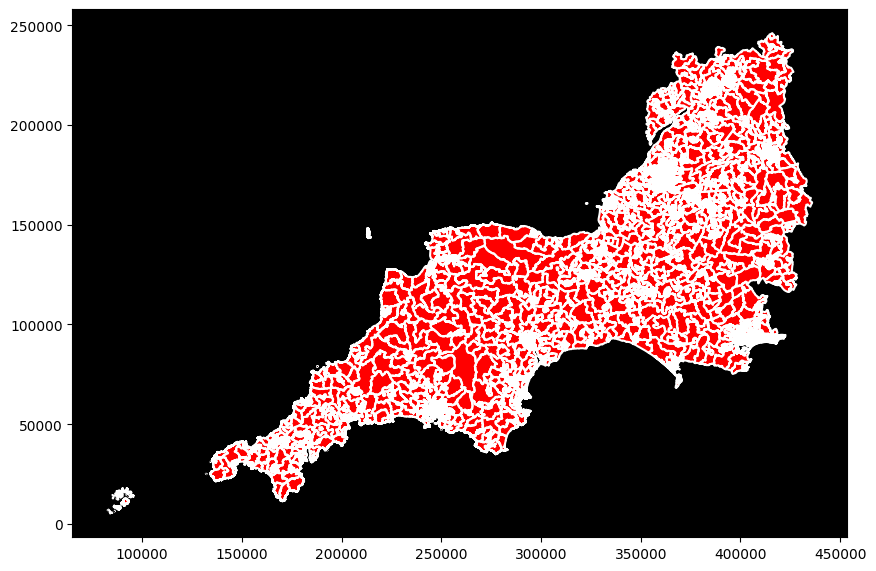

In [122]:
ax = lsoa_sw.boundary.plot(figsize=(10,10), color="white")

ax.set_facecolor('black')

lsoa_sw['geometry'].plot(
    ax=ax,
    color="red",
    markersize=5
)

In [123]:
poi_count = (
    poi_sw_lsoa
    .groupby("LSOA21CD")
    .size()
    .reset_index(name="poi_count")
)

In [124]:
poi_count

,LSOA21CD,poi_count
0,E01014370,1022
1,E01014371,349
2,E01014372,299
3,E01014373,84
4,E01014374,69
...,...,...
3401,E01035229,67
3402,E01035230,42
3403,E01035231,10
3404,E01035232,75


In [125]:
df_poi_sw

,ref_no,name,pointx_class,groupname,categoryname,classname,feature_easting,feature_northing,pos_accuracy,uprn,...,telephone_number,url,brand,qualifier_type,qualifier_data,provenance,supply_date,source_file,source_folder,geometry
0,166806215,Carrs Volkswagen Van Centre Indian Queens,09490695,Retail,Motoring,New Vehicles,192388.0,59304.0,1,1.003463e+10,...,01726259107,www.volkswagen.co.uk,Volkswagen,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (192388.001 59303.999)
1,166806217,Carrs Select Scorrier,09490695,Retail,Motoring,New Vehicles,172473.0,44630.0,1,NaN,...,01872398599,NaN,Helston Garages Group,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (172473.001 44629.999)
2,166806224,Vertu Volvo Truro,09490695,Retail,Motoring,New Vehicles,177715.0,45002.0,1,1.000410e+11,...,01872461413,www.vertumotors.com,Volvo,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (177715.001 45001.999)
3,166806225,Carrs Land Rover,09490695,Retail,Motoring,New Vehicles,172552.0,44706.0,1,1.000121e+10,...,01872398387,NaN,Land Rover,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (172552.001 44705.999)
4,181524408,Exeter Van Store,09490695,Retail,Motoring,New Vehicles,291945.6,90995.5,1,1.001304e+10,...,01392424150,www.hendycarstore.co.uk,Hendy Group,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (291945.601 90995.499)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
391259,170996524,Unique Cleaning Group,02070100,Commercial Services,Contract Services,Contract Cleaning Services,394673.5,222729.5,1,1.001214e+11,...,01242339099,NaN,NaN,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (394673.501 222729.5)
391260,64371470,Margaret Reid Display Solutions,02070101,Commercial Services,Contract Services,Display and Window Dressers,384301.0,201139.0,1,1.001214e+11,...,01453835555,NaN,NaN,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (384301.001 201139)
391261,104573666,Daktronics,02070101,Commercial Services,Contract Services,Display and Window Dressers,381424.0,212678.0,1,1.000731e+10,...,01454413606,NaN,NaN,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (381424.001 212678)
391262,161943034,Vod Visual,02070101,Commercial Services,Contract Services,Display and Window Dressers,411315.0,183056.3,1,1.009004e+10,...,07794229602,www.vod-visual.co.uk,NaN,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (411315.001 183056.299)


In [126]:
poi_sw_lsoa

,ref_no,name,pointx_class,groupname,categoryname,classname,feature_easting,feature_northing,pos_accuracy,uprn,...,qualifier_type,qualifier_data,provenance,supply_date,source_file,source_folder,geometry,index_right,LSOA21CD,LSOA21NM
0,166806215,Carrs Volkswagen Van Centre Indian Queens,09490695,Retail,Motoring,New Vehicles,192388.0,59304.0,1,1.003463e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (192388.001 59303.999),18079.0,E01019063,Cornwall 019D
1,166806217,Carrs Select Scorrier,09490695,Retail,Motoring,New Vehicles,172473.0,44630.0,1,NaN,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (172473.001 44629.999),17846.0,E01018820,Cornwall 047D
2,166806224,Vertu Volvo Truro,09490695,Retail,Motoring,New Vehicles,177715.0,45002.0,1,1.000410e+11,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (177715.001 45001.999),17845.0,E01018819,Cornwall 043A
3,166806225,Carrs Land Rover,09490695,Retail,Motoring,New Vehicles,172552.0,44706.0,1,1.000121e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (172552.001 44705.999),17846.0,E01018820,Cornwall 047D
4,181524408,Exeter Van Store,09490695,Retail,Motoring,New Vehicles,291945.6,90995.5,1,1.001304e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426697.gpkg,poi_6426697,POINT (291945.601 90995.499),18949.0,E01019969,Exeter 014B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
391259,170996524,Unique Cleaning Group,02070100,Commercial Services,Contract Services,Contract Cleaning Services,394673.5,222729.5,1,1.001214e+11,...,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (394673.501 222729.5),21041.0,E01022153,Cheltenham 004D
391260,64371470,Margaret Reid Display Solutions,02070101,Commercial Services,Contract Services,Display and Window Dressers,384301.0,201139.0,1,1.001214e+11,...,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (384301.001 201139),21228.0,E01022350,Stroud 010A
391261,104573666,Daktronics,02070101,Commercial Services,Contract Services,Display and Window Dressers,381424.0,212678.0,1,1.000731e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (381424.001 212678),32835.0,E01034797,Gloucester 015K
391262,161943034,Vod Visual,02070101,Commercial Services,Contract Services,Display and Window Dressers,411315.0,183056.3,1,1.009004e+10,...,NaN,NaN,118 Information,2026-03-01,poi_6426711.gpkg,poi_6426711,POINT (411315.001 183056.299),14718.0,E01015501,Swindon 022A


In [127]:
poi_group_wide = (
    poi_sw_lsoa
    .groupby(["LSOA21CD", "groupname"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

poi_group_wide.head()

groupname,LSOA21CD,"Accommodation, Eating and Drinking",Attractions,Commercial Services,Education and Health,Manufacturing and Production,Public Infrastructure,Retail,Sport and Entertainment,Transport
0,E01014370,216,40,257,52,40,77,286,21,33
1,E01014371,59,29,68,12,8,54,50,16,53
2,E01014372,53,24,124,25,17,13,37,2,4
3,E01014373,4,2,21,6,4,17,6,1,23
4,E01014374,3,0,2,2,1,31,1,2,27


In [128]:
poi_group_wide.columns

Index(['LSOA21CD', 'Accommodation, Eating and Drinking', 'Attractions',
       'Commercial Services', 'Education and Health',
       'Manufacturing and Production', 'Public Infrastructure', 'Retail',
       'Sport and Entertainment', 'Transport'],
      dtype='str', name='groupname')

In [129]:
poi_group_wide.columns.name = None

poi_group_wide.columns = [
    col if col == "LSOA21CD"
    else col.lower()
            .replace(" ", "_")
            .replace(",", "")
    for col in poi_group_wide.columns
]

In [130]:
poi_group_wide.columns

Index(['LSOA21CD', 'accommodation_eating_and_drinking', 'attractions',
       'commercial_services', 'education_and_health',
       'manufacturing_and_production', 'public_infrastructure', 'retail',
       'sport_and_entertainment', 'transport'],
      dtype='str')

In [131]:
poi_group_density = lsoa_density2[
    ["LSOA21CD", "area_km2"]
].merge(
    poi_group_wide,
    on="LSOA21CD",
    how="left"
)

In [132]:
poi_group_density

,LSOA21CD,area_km2,accommodation_eating_and_drinking,attractions,commercial_services,education_and_health,manufacturing_and_production,public_infrastructure,retail,sport_and_entertainment,transport
0,E01014370,0.377030,216.0,40.0,257.0,52.0,40.0,77.0,286.0,21.0,33.0
1,E01014371,0.409491,59.0,29.0,68.0,12.0,8.0,54.0,50.0,16.0,53.0
2,E01014372,0.166801,53.0,24.0,124.0,25.0,17.0,13.0,37.0,2.0,4.0
3,E01014373,1.059979,4.0,2.0,21.0,6.0,4.0,17.0,6.0,1.0,23.0
4,E01014374,5.002127,3.0,0.0,2.0,2.0,1.0,31.0,1.0,2.0,27.0
...,...,...,...,...,...,...,...,...,...,...,...
3402,E01035229,0.580155,6.0,1.0,14.0,6.0,6.0,17.0,4.0,4.0,9.0
3403,E01035230,0.632230,8.0,4.0,5.0,0.0,0.0,9.0,2.0,3.0,11.0
3404,E01035231,0.440986,0.0,3.0,3.0,1.0,0.0,3.0,0.0,0.0,0.0
3405,E01035232,0.652123,5.0,6.0,20.0,5.0,0.0,19.0,3.0,1.0,16.0


In [133]:
poi_cols = poi_group_wide.columns.drop("LSOA21CD")

poi_group_density[poi_cols] = (
    poi_group_density[poi_cols]
    .fillna(0)
)

In [134]:
for col in poi_cols:
    poi_group_density[f"{col}_density"] = (
        poi_group_density[col]
        / poi_group_density["area_km2"]
    )

In [135]:
poi_group_density

,LSOA21CD,area_km2,accommodation_eating_and_drinking,attractions,commercial_services,education_and_health,manufacturing_and_production,public_infrastructure,retail,sport_and_entertainment,transport,accommodation_eating_and_drinking_density,attractions_density,commercial_services_density,education_and_health_density,manufacturing_and_production_density,public_infrastructure_density,retail_density,sport_and_entertainment_density,transport_density
0,E01014370,0.377030,216.0,40.0,257.0,52.0,40.0,77.0,286.0,21.0,33.0,572.898314,106.092280,681.642902,137.919965,106.092280,204.227640,758.559805,55.698447,87.526131
1,E01014371,0.409491,59.0,29.0,68.0,12.0,8.0,54.0,50.0,16.0,53.0,144.081440,70.819691,166.059964,29.304700,19.536466,131.871148,122.102915,39.072933,129.429090
2,E01014372,0.166801,53.0,24.0,124.0,25.0,17.0,13.0,37.0,2.0,4.0,317.742958,143.883604,743.398618,149.878754,101.917553,77.936952,221.820555,11.990300,23.980601
3,E01014373,1.059979,4.0,2.0,21.0,6.0,4.0,17.0,6.0,1.0,23.0,3.773658,1.886829,19.811705,5.660487,3.773658,16.038047,5.660487,0.943415,21.698534
4,E01014374,5.002127,3.0,0.0,2.0,2.0,1.0,31.0,1.0,2.0,27.0,0.599745,0.000000,0.399830,0.399830,0.199915,6.197363,0.199915,0.399830,5.397703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3402,E01035229,0.580155,6.0,1.0,14.0,6.0,6.0,17.0,4.0,4.0,9.0,10.342064,1.723677,24.131482,10.342064,10.342064,29.302514,6.894709,6.894709,15.513095
3403,E01035230,0.632230,8.0,4.0,5.0,0.0,0.0,9.0,2.0,3.0,11.0,12.653614,6.326807,7.908509,0.000000,0.000000,14.235316,3.163403,4.745105,17.398719
3404,E01035231,0.440986,0.0,3.0,3.0,1.0,0.0,3.0,0.0,0.0,0.0,0.000000,6.802944,6.802944,2.267648,0.000000,6.802944,0.000000,0.000000,0.000000
3405,E01035232,0.652123,5.0,6.0,20.0,5.0,0.0,19.0,3.0,1.0,16.0,7.667270,9.200723,30.669078,7.667270,0.000000,29.135624,4.600362,1.533454,24.535263


In [136]:
# count intersections

In [137]:
intersection_count = (
    intersections_sw_lsoa
    .dropna(subset=["LSOA21CD"])
    .groupby("LSOA21CD")
    .size()
    .reset_index(name="intersection_count")
)

In [138]:
intersection_count

,LSOA21CD,intersection_count
0,E01014370,87
1,E01014371,57
2,E01014372,27
3,E01014373,40
4,E01014374,65
...,...,...
3401,E01035229,87
3402,E01035230,100
3403,E01035231,47
3404,E01035232,114


In [139]:
lsoa_density

,LSOA21CD,LSOA21NM,LSOA21NMW,BNG_E,BNG_N,LAT,LONG,GlobalID,geometry,area_km2
13647,E01014370,Bath and North East Somerset 007A,,375084,164994,51.383438,-2.35942,{4803A59D-E95B-4FE6-BEB0-E69E84BD7D48},"MULTIPOLYGON (((375292.289 165633.714, 375288....",0.377030
13648,E01014371,Bath and North East Somerset 007B,,375328,164841,51.382069,-2.35590,{9C5F2B67-06C6-477C-83FF-A8DEFC8C184F},"MULTIPOLYGON (((375624.781 165202.406, 375619....",0.409491
13649,E01014372,Bath and North East Somerset 007C,,374832,165378,51.386879,-2.36307,{34817845-639D-4BDC-85F2-3650D6948257},"MULTIPOLYGON (((375327.102 165666.338, 375313....",0.166801
13650,E01014373,Bath and North East Somerset 010A,,377791,167691,51.407799,-2.32069,{CF46DDA7-D5D4-4F32-883D-D6813023538C},"MULTIPOLYGON (((377762.251 168340.474, 377738....",1.059979
13651,E01014374,Bath and North East Somerset 010B,,378059,166769,51.399521,-2.31678,{9B5DFE41-266E-4AB9-813E-8592E3AC4BB0},"MULTIPOLYGON (((378818.843 167715.55, 378817.4...",5.002127
...,...,...,...,...,...,...,...,...,...,...
33223,E01035229,South Gloucestershire 035C,,361662,178206,51.501480,-2.55372,{FFCFBCDA-4686-4F28-BCB2-87F483316D15},"MULTIPOLYGON (((362036.795 178559.778, 362035....",0.580155
33224,E01035230,South Gloucestershire 035D,,361216,178172,51.501141,-2.56014,{75AF98C1-D8D9-4FA8-8123-12C67DF32C60},"MULTIPOLYGON (((361548.098 178707.611, 361546 ...",0.632230
33225,E01035231,South Gloucestershire 035E,,361945,177516,51.495300,-2.54956,{FFE85EA9-855F-4746-B64D-7DA442E1FEAB},"MULTIPOLYGON (((361922.063 177801.938, 361918....",0.440986
33226,E01035232,South Gloucestershire 036B,,362900,179544,51.513592,-2.53602,{17EEB482-0456-4254-926A-BCA01EA1C8E3},"MULTIPOLYGON (((363286 179964, 363286 179978, ...",0.652123


In [140]:
# count crime

In [141]:
crime_count = (
    df_crime_sw
    .groupby("LSOA21CD")
    .size()
    .reset_index(name="crime_count")
)

In [142]:
# calculate signatures macro group

In [143]:
macro_signature = (
    signatures_lsoa_no_outlier
    .groupby(
        ["LSOA21CD", "macro_group"],
        as_index=False
    )["signature_area_km2"]
    .sum()
)

In [144]:
macro_signature["total_signature_area_km2"] = (
    macro_signature
    .groupby("LSOA21CD")["signature_area_km2"]
    .transform("sum")
)

In [145]:
macro_signature["signature_proportion"] = (
    macro_signature["signature_area_km2"]
    / macro_signature["total_signature_area_km2"]
)

In [146]:
macro_signature

,LSOA21CD,macro_group,signature_area_km2,total_signature_area_km2,signature_proportion
0,E01014370,Urban,377.030259,377.030259,1.000000
1,E01014371,Suburban,35.342696,409.490633,0.086309
2,E01014371,Urban,374.147938,409.490633,0.913691
3,E01014372,Urban,166.801494,166.801494,1.000000
4,E01014373,Rural,76.195479,1059.979463,0.071884
...,...,...,...,...,...
5188,E01035230,Urban,211.144672,632.230447,0.333968
5189,E01035231,Suburban,378.816291,440.985542,0.859022
5190,E01035231,Urban,62.169251,440.985542,0.140978
5191,E01035232,Suburban,652.122630,652.122630,1.000000


In [147]:
macro_signature_wide = (
    macro_signature
    .pivot(
        index="LSOA21CD",
        columns="macro_group",
        values="signature_proportion"
    )
    .fillna(0)
    .reset_index()
)

In [148]:
macro_signature_wide

macro_group,LSOA21CD,Rural,Suburban,Urban
0,E01014370,0.000000,0.000000,1.000000
1,E01014371,0.000000,0.086309,0.913691
2,E01014372,0.000000,0.000000,1.000000
3,E01014373,0.071884,0.928116,0.000000
4,E01014374,0.088861,0.911139,0.000000
...,...,...,...,...
3402,E01035229,0.000000,0.956070,0.043930
3403,E01035230,0.000000,0.666032,0.333968
3404,E01035231,0.000000,0.859022,0.140978
3405,E01035232,0.000000,1.000000,0.000000


In [149]:
macro_signature_wide = macro_signature_wide.rename(
    columns={
        "Urban": "urban_part",
        "Suburban": "suburban_part",
        "Rural": "rural_part",
        "Other": "other_part"
    }
)

In [150]:
macro_signature_wide

macro_group,LSOA21CD,rural_part,suburban_part,urban_part
0,E01014370,0.000000,0.000000,1.000000
1,E01014371,0.000000,0.086309,0.913691
2,E01014372,0.000000,0.000000,1.000000
3,E01014373,0.071884,0.928116,0.000000
4,E01014374,0.088861,0.911139,0.000000
...,...,...,...,...
3402,E01035229,0.000000,0.956070,0.043930
3403,E01035230,0.000000,0.666032,0.333968
3404,E01035231,0.000000,0.859022,0.140978
3405,E01035232,0.000000,1.000000,0.000000


In [151]:
macro_signature_wide["macro_prop_sum"] = (
    macro_signature_wide[
        ["urban_part", "suburban_part", "rural_part"]
    ].sum(axis=1)
)

macro_signature_wide["macro_prop_sum"].describe()

count    3.407000e+03
mean     1.000000e+00
std      3.698570e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: macro_prop_sum, dtype: float64

In [152]:
lsoa_density = lsoa_density.merge(
        poi_count[["LSOA21CD", "poi_count"]],
        on="LSOA21CD",
        how="left"
    ).merge(
        intersection_count[
            ["LSOA21CD", "intersection_count"]
        ],
        on="LSOA21CD",
        how="left"
    ).merge(
        crime_count[["LSOA21CD", "crime_count"]],
        on="LSOA21CD",
        how="left"
    ).merge(
        df_pop_sw[["LSOA21CD", "total_pop", "65+_pop"]],
        on="LSOA21CD",
        how="left"
    ).merge(
        macro_signature_wide[
            [
                "LSOA21CD",
                "urban_part",
                "suburban_part",
                "rural_part"
            ]
        ],
        on="LSOA21CD",
        how="left"
    ).merge(
        df_imd_sw[
            [
                "LSOA21CD",
                "IMD Rank",
                "IMD Decile"
            ]
        ],
        on="LSOA21CD",
        how="left"
    )

lsoa_density[
    ["poi_count", "intersection_count"]
] = lsoa_density[
    ["poi_count", "intersection_count"]
].fillna(0)

# lsoa_density["poi_density_km2"] = (
#     lsoa_density["poi_count"] / lsoa_density["area_km2"]
# )
#
lsoa_density["intersection_density_km2"] = (
    lsoa_density["intersection_count"]
    / lsoa_density["area_km2"]
)
#
# lsoa_density["crime_rate"] = (
#         lsoa_density["crime_rate"]
#     / lsoa_density["area_km2"]
# )

In [153]:
lsoa_density

,LSOA21CD,LSOA21NM,LSOA21NMW,BNG_E,BNG_N,LAT,LONG,GlobalID,geometry,area_km2,...,intersection_count,crime_count,total_pop,65+_pop,urban_part,suburban_part,rural_part,IMD Rank,IMD Decile,intersection_density_km2
0,E01014370,Bath and North East Somerset 007A,,375084,164994,51.383438,-2.35942,{4803A59D-E95B-4FE6-BEB0-E69E84BD7D48},"MULTIPOLYGON (((375292.289 165633.714, 375288....",0.377030,...,87.0,4470,1931,0.232004,1.000000,0.000000,0.000000,9550,3,230.750710
1,E01014371,Bath and North East Somerset 007B,,375328,164841,51.382069,-2.35590,{9C5F2B67-06C6-477C-83FF-A8DEFC8C184F},"MULTIPOLYGON (((375624.781 165202.406, 375619....",0.409491,...,57.0,3033,2163,0.171983,0.913691,0.086309,0.000000,14815,5,139.197323
2,E01014372,Bath and North East Somerset 007C,,374832,165378,51.386879,-2.36307,{34817845-639D-4BDC-85F2-3650D6948257},"MULTIPOLYGON (((375327.102 165666.338, 375313....",0.166801,...,27.0,2103,1894,0.137276,1.000000,0.000000,0.000000,16751,5,161.869054
3,E01014373,Bath and North East Somerset 010A,,377791,167691,51.407799,-2.32069,{CF46DDA7-D5D4-4F32-883D-D6813023538C},"MULTIPOLYGON (((377762.251 168340.474, 377738....",1.059979,...,40.0,186,1570,0.149045,0.000000,0.928116,0.071884,21077,7,37.736580
4,E01014374,Bath and North East Somerset 010B,,378059,166769,51.399521,-2.31678,{9B5DFE41-266E-4AB9-813E-8592E3AC4BB0},"MULTIPOLYGON (((378818.843 167715.55, 378817.4...",5.002127,...,65.0,126,1619,0.235948,0.000000,0.911139,0.088861,28121,9,12.994471
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3402,E01035229,South Gloucestershire 035C,,361662,178206,51.501480,-2.55372,{FFCFBCDA-4686-4F28-BCB2-87F483316D15},"MULTIPOLYGON (((362036.795 178559.778, 362035....",0.580155,...,87.0,351,3366,0.009210,0.043930,0.956070,0.000000,25356,8,149.959922
3403,E01035230,South Gloucestershire 035D,,361216,178172,51.501141,-2.56014,{75AF98C1-D8D9-4FA8-8123-12C67DF32C60},"MULTIPOLYGON (((361548.098 178707.611, 361546 ...",0.632230,...,100.0,585,1443,0.039501,0.333968,0.666032,0.000000,30622,10,158.170174
3404,E01035231,South Gloucestershire 035E,,361945,177516,51.495300,-2.54956,{FFE85EA9-855F-4746-B64D-7DA442E1FEAB},"MULTIPOLYGON (((361922.063 177801.938, 361918....",0.440986,...,47.0,153,1445,0.033910,0.140978,0.859022,0.000000,32919,10,106.579458
3405,E01035232,South Gloucestershire 036B,,362900,179544,51.513592,-2.53602,{17EEB482-0456-4254-926A-BCA01EA1C8E3},"MULTIPOLYGON (((363286 179964, 363286 179978, ...",0.652123,...,114.0,561,2135,0.120375,0.000000,1.000000,0.000000,22980,7,174.813746


In [154]:
count_columns = [
    "intersection_count",
    "crime_count"
]

lsoa_density[count_columns] = (
    lsoa_density[count_columns]
    .fillna(0)
)

signature_columns = [
    "urban_part",
    "suburban_part",
    "rural_part"
]

lsoa_density[signature_columns] = (
    lsoa_density[signature_columns]
    .fillna(0)
)

In [155]:
lsoa_density["poi_density_km2"] = (
    lsoa_density["poi_count"]
    / lsoa_density["area_km2"]
)

lsoa_density["intersection_density_km2"] = (
    lsoa_density["intersection_count"]
    / lsoa_density["area_km2"]
)

In [156]:
lsoa_density["crime_rate_1000"] = (
    lsoa_density["crime_count"]
    / lsoa_density["total_pop"]
    * 1_000
)

In [157]:
poi_group_density.columns

Index(['LSOA21CD', 'area_km2', 'accommodation_eating_and_drinking',
       'attractions', 'commercial_services', 'education_and_health',
       'manufacturing_and_production', 'public_infrastructure', 'retail',
       'sport_and_entertainment', 'transport',
       'accommodation_eating_and_drinking_density', 'attractions_density',
       'commercial_services_density', 'education_and_health_density',
       'manufacturing_and_production_density', 'public_infrastructure_density',
       'retail_density', 'sport_and_entertainment_density',
       'transport_density'],
      dtype='str')

In [158]:
lsoa_density2

,LSOA21CD,LSOA21NM,LSOA21NMW,BNG_E,BNG_N,LAT,LONG,GlobalID,geometry,area_km2
13647,E01014370,Bath and North East Somerset 007A,,375084,164994,51.383438,-2.35942,{4803A59D-E95B-4FE6-BEB0-E69E84BD7D48},"MULTIPOLYGON (((375292.289 165633.714, 375288....",0.377030
13648,E01014371,Bath and North East Somerset 007B,,375328,164841,51.382069,-2.35590,{9C5F2B67-06C6-477C-83FF-A8DEFC8C184F},"MULTIPOLYGON (((375624.781 165202.406, 375619....",0.409491
13649,E01014372,Bath and North East Somerset 007C,,374832,165378,51.386879,-2.36307,{34817845-639D-4BDC-85F2-3650D6948257},"MULTIPOLYGON (((375327.102 165666.338, 375313....",0.166801
13650,E01014373,Bath and North East Somerset 010A,,377791,167691,51.407799,-2.32069,{CF46DDA7-D5D4-4F32-883D-D6813023538C},"MULTIPOLYGON (((377762.251 168340.474, 377738....",1.059979
13651,E01014374,Bath and North East Somerset 010B,,378059,166769,51.399521,-2.31678,{9B5DFE41-266E-4AB9-813E-8592E3AC4BB0},"MULTIPOLYGON (((378818.843 167715.55, 378817.4...",5.002127
...,...,...,...,...,...,...,...,...,...,...
33223,E01035229,South Gloucestershire 035C,,361662,178206,51.501480,-2.55372,{FFCFBCDA-4686-4F28-BCB2-87F483316D15},"MULTIPOLYGON (((362036.795 178559.778, 362035....",0.580155
33224,E01035230,South Gloucestershire 035D,,361216,178172,51.501141,-2.56014,{75AF98C1-D8D9-4FA8-8123-12C67DF32C60},"MULTIPOLYGON (((361548.098 178707.611, 361546 ...",0.632230
33225,E01035231,South Gloucestershire 035E,,361945,177516,51.495300,-2.54956,{FFE85EA9-855F-4746-B64D-7DA442E1FEAB},"MULTIPOLYGON (((361922.063 177801.938, 361918....",0.440986
33226,E01035232,South Gloucestershire 036B,,362900,179544,51.513592,-2.53602,{17EEB482-0456-4254-926A-BCA01EA1C8E3},"MULTIPOLYGON (((363286 179964, 363286 179978, ...",0.652123


In [159]:
lsoa_density2 = lsoa_density2.merge(
        poi_group_density[["LSOA21CD" ,
                           "accommodation_eating_and_drinking_density",
                           "attractions_density",
                           "commercial_services_density",
                           "education_and_health_density",
                           "manufacturing_and_production_density",
                           "public_infrastructure_density",
                           "retail_density",
                           "sport_and_entertainment_density",
                           "transport_density"]],
        on="LSOA21CD",
        how="left"
    ).merge(
        intersection_count[
            ["LSOA21CD", "intersection_count"]
        ],
        on="LSOA21CD",
        how="left"
    ).merge(
        crime_count[["LSOA21CD", "crime_count"]],
        on="LSOA21CD",
        how="left"
    ).merge(
        df_pop_sw[["LSOA21CD", "total_pop", "65+_pop"]],
        on="LSOA21CD",
        how="left"
    ).merge(
        macro_signature_wide[
            [
                "LSOA21CD",
                "urban_part",
                "suburban_part",
                "rural_part"
            ]
        ],
        on="LSOA21CD",
        how="left"
    ).merge(
        df_imd_sw[
            [
                "LSOA21CD",
                "IMD Rank",
                "IMD Decile"
            ]
        ],
        on="LSOA21CD",
        how="left"
    ).merge(
        income_employ_sw[
            [
                "LSOA21CD",
                "Income Rank",
                "Income Decile",
                "Employment Rank",
                "Employment Decile"
            ]
        ],
        on="LSOA21CD",
        how="left"
)

lsoa_density2[
    ["intersection_count"]
] = lsoa_density2[
    ["intersection_count"]
].fillna(0)

# lsoa_density["poi_density_km2"] = (
#     lsoa_density["poi_count"] / lsoa_density["area_km2"]
# )
#
# lsoa_density["intersection_density_km2"] = (
#     lsoa_density["intersection_count"]
#     / lsoa_density["area_km2"]
# )
#
# lsoa_density["crime_rate"]

In [160]:
lsoa_density2 = lsoa_density2.drop(columns="LSOA21NMW")

In [161]:
lsoa_density2

,LSOA21CD,LSOA21NM,BNG_E,BNG_N,LAT,LONG,GlobalID,geometry,area_km2,accommodation_eating_and_drinking_density,...,65+_pop,urban_part,suburban_part,rural_part,IMD Rank,IMD Decile,Income Rank,Income Decile,Employment Rank,Employment Decile
0,E01014370,Bath and North East Somerset 007A,375084,164994,51.383438,-2.35942,{4803A59D-E95B-4FE6-BEB0-E69E84BD7D48},"MULTIPOLYGON (((375292.289 165633.714, 375288....",0.377030,572.898314,...,0.232004,1.000000,0.000000,0.000000,9550,3,13023,4,12849,4
1,E01014371,Bath and North East Somerset 007B,375328,164841,51.382069,-2.35590,{9C5F2B67-06C6-477C-83FF-A8DEFC8C184F},"MULTIPOLYGON (((375624.781 165202.406, 375619....",0.409491,144.081440,...,0.171983,0.913691,0.086309,0.000000,14815,5,26693,8,22402,7
2,E01014372,Bath and North East Somerset 007C,374832,165378,51.386879,-2.36307,{34817845-639D-4BDC-85F2-3650D6948257},"MULTIPOLYGON (((375327.102 165666.338, 375313....",0.166801,317.742958,...,0.137276,1.000000,0.000000,0.000000,16751,5,23396,7,21101,7
3,E01014373,Bath and North East Somerset 010A,377791,167691,51.407799,-2.32069,{CF46DDA7-D5D4-4F32-883D-D6813023538C},"MULTIPOLYGON (((377762.251 168340.474, 377738....",1.059979,3.773658,...,0.149045,0.000000,0.928116,0.071884,21077,7,18084,6,21237,7
4,E01014374,Bath and North East Somerset 010B,378059,166769,51.399521,-2.31678,{9B5DFE41-266E-4AB9-813E-8592E3AC4BB0},"MULTIPOLYGON (((378818.843 167715.55, 378817.4...",5.002127,0.599745,...,0.235948,0.000000,0.911139,0.088861,28121,9,24108,8,25862,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3402,E01035229,South Gloucestershire 035C,361662,178206,51.501480,-2.55372,{FFCFBCDA-4686-4F28-BCB2-87F483316D15},"MULTIPOLYGON (((362036.795 178559.778, 362035....",0.580155,10.342064,...,0.009210,0.043930,0.956070,0.000000,25356,8,27874,9,32746,10
3403,E01035230,South Gloucestershire 035D,361216,178172,51.501141,-2.56014,{75AF98C1-D8D9-4FA8-8123-12C67DF32C60},"MULTIPOLYGON (((361548.098 178707.611, 361546 ...",0.632230,12.653614,...,0.039501,0.333968,0.666032,0.000000,30622,10,21421,7,29740,9
3404,E01035231,South Gloucestershire 035E,361945,177516,51.495300,-2.54956,{FFE85EA9-855F-4746-B64D-7DA442E1FEAB},"MULTIPOLYGON (((361922.063 177801.938, 361918....",0.440986,0.000000,...,0.033910,0.140978,0.859022,0.000000,32919,10,31495,10,33594,10
3405,E01035232,South Gloucestershire 036B,362900,179544,51.513592,-2.53602,{17EEB482-0456-4254-926A-BCA01EA1C8E3},"MULTIPOLYGON (((363286 179964, 363286 179978, ...",0.652123,7.667270,...,0.120375,0.000000,1.000000,0.000000,22980,7,14296,5,18580,6


In [162]:
lsoa_density2["intersection_density"] = (
    lsoa_density2["intersection_count"]
    / lsoa_density2["area_km2"]
)

lsoa_density2["crime_density"] = (
    lsoa_density2["crime_count"]
    / lsoa_density2["area_km2"]
)

lsoa_density2["crime_rate_1000"] = (
    lsoa_density2["crime_count"]
    / lsoa_density2["total_pop"] *1_000
)

lsoa_density2["pop_density"] =(
    lsoa_density2["total_pop"]
    / lsoa_density2["area_km2"]
)

In [167]:
print(lsoa_density2.head())

    LSOA21CD                           LSOA21NM  \
0  E01014370  Bath and North East Somerset 007A   
1  E01014371  Bath and North East Somerset 007B   
2  E01014372  Bath and North East Somerset 007C   
3  E01014373  Bath and North East Somerset 010A   
4  E01014374  Bath and North East Somerset 010B   

                                 GlobalID  \
0  {4803A59D-E95B-4FE6-BEB0-E69E84BD7D48}   
1  {9C5F2B67-06C6-477C-83FF-A8DEFC8C184F}   
2  {34817845-639D-4BDC-85F2-3650D6948257}   
3  {CF46DDA7-D5D4-4F32-883D-D6813023538C}   
4  {9B5DFE41-266E-4AB9-813E-8592E3AC4BB0}   

                                            geometry  area_km2  \
0  MULTIPOLYGON (((375292.289 165633.714, 375288....  0.377030   
1  MULTIPOLYGON (((375624.781 165202.406, 375619....  0.409491   
2  MULTIPOLYGON (((375327.102 165666.338, 375313....  0.166801   
3  MULTIPOLYGON (((377762.251 168340.474, 377738....  1.059979   
4  MULTIPOLYGON (((378818.843 167715.55, 378817.4...  5.002127   

   accommodation_eating_a

In [164]:
lsoa_density2 = lsoa_density2.drop(columns=["BNG_E", "BNG_N", "LAT", "LONG"])

In [165]:
lsoa_density2_path = Path("Data/regression/lsoa_dataset_complete.gpkg")
lsoa_density2.to_file(lsoa_density2_path, driver = "GPKG")

## Maps

In [166]:
# map major cities points

In [169]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import contextily as ctx

In [173]:
# Function to save figures

def save_fig(fig, filename, folder="Figures", dpi=300):

    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)

    filepath = folder / f"{filename}.png"

    fig.savefig(
        filepath,
        dpi=dpi,
        bbox_inches="tight"
    )

    print(f"Figure saved to: {filepath}")

In [167]:
# Import big cities boundaries

cities_bound_path = Path("Data/Major_Towns_and_Cities_Dec_2015_Boundaries_V2_2022_5202522928287298099.gpkg")

cities_bound = gpd.read_file(cities_bound_path, engine="pyogrio")

In [168]:
# cities_sw_bound = gpd.sjoin(
#     cities_bound, lsoa_sw["geometry"],
#      how="left",
#     predicate="within"
# )

# Make sure both datasets use the same CRS
cities_bound = cities_bound.to_crs(lsoa_sw.crs)

# Combine all South West LSOAs into one regional boundary
sw_bound = lsoa_sw[['geometry']].dissolve()

# Clip city polygons to the South West boundary
cities_sw_bound = gpd.sjoin(
    cities_bound,
    sw_bound,
    how="inner",
    predicate="intersects"
).drop(columns="index_right")

In [169]:
# City Points

city_points_sw = gpd.GeoDataFrame(cities_sw_bound, geometry=gpd.points_from_xy(cities_sw_bound.LONG, cities_sw_bound.LAT), crs='EPSG:4326')

city_points_sw = city_points_sw.to_crs(df_poi_sw.crs)

In [170]:
# South West Boundaries
sw_bound_lines = sw_bound[['geometry']].dissolve()

In [171]:
from shapely.ops import unary_union

sw_bound_outline = unary_union(sw_bound_lines.geometry)

In [172]:
city_centres = pd.DataFrame({
    "city": [
        "Bristol",
        "Bath",
        "Exeter",
        "Plymouth",
        "Gloucester",
        "Cheltenham",
        "Swindon",
        "Bournemouth",
        "Torquay"
    ],
    "longitude": [
        -2.5879,
        -2.3590,
        -3.5339,
        -4.1427,
        -2.2426,
        -2.0783,
        -1.7837,
        -1.8795,
        -3.5253
    ],
    "latitude": [
        51.4545,
        51.3811,
        50.7184,
        50.3755,
        51.8642,
        51.8994,
        51.5558,
        50.7192,
        50.4619
    ]
})

city_centres = gpd.GeoDataFrame(
    city_centres,
    geometry=gpd.points_from_xy(
        city_centres["longitude"],
        city_centres["latitude"]
    ),
    crs="EPSG:4326"
)

city_centres = city_centres.to_crs(df_poi_sw.crs)

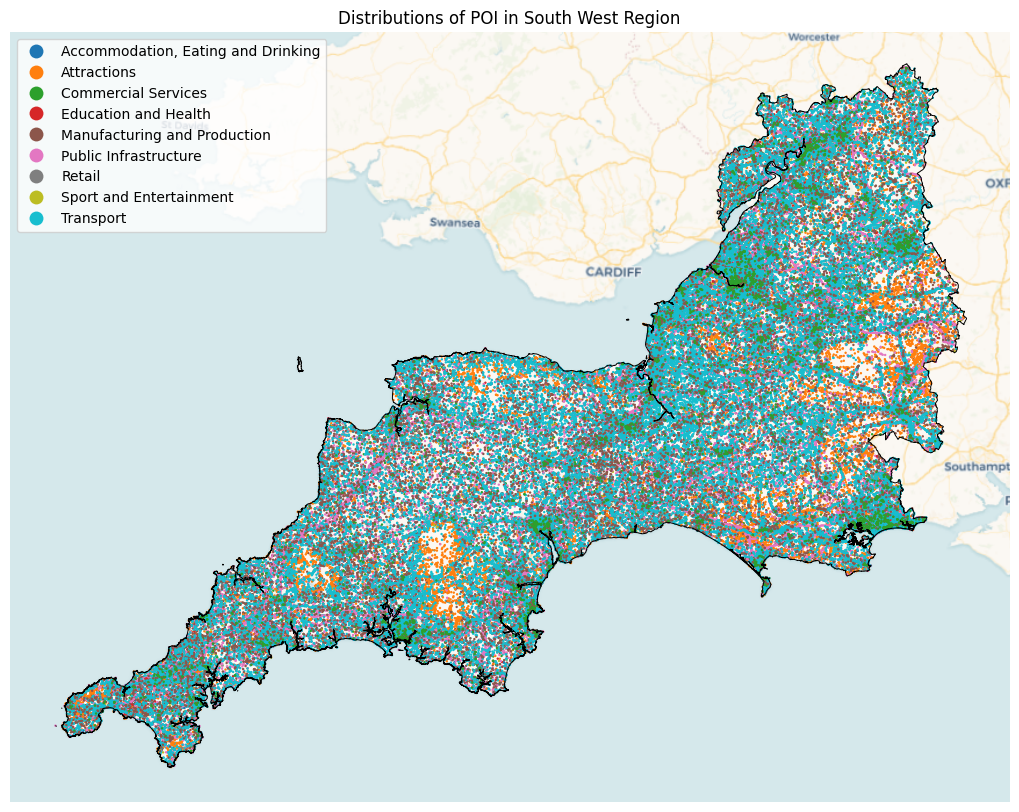

In [196]:
fig, ax = plt.subplots(figsize=(20, 10))

custom_url = "https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}.png?key=cb1_2r02_1_5bbac75c503cda41f2d08b96"


# tableau = ListedColormap([
#     "#4E79A7",
#     "#F28E2B",
#     "#E15759",
#     "#76B7B2",
#     "#59A14F",
#     "#EDC948",
#     "#B07AA1",
#     "#FF9DA7",
#     "#9C755F"
# ])

df_poi_sw.plot(
    column="groupname",
    cmap="tab10",
    legend=True,
    edgecolor="none",
    marker = "o",
    markersize = 3,
    ax=ax
)

# after plotting POIs
ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=custom_url
)


gpd.GeoSeries([sw_bound_outline], crs=sw_bound.crs).boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.7
)

# city_centres.plot(
#     ax=ax,
#     color="black",
#     marker="o",
#     markersize=25,
#     edgecolor="white",
#     linewidth=0.8,
#     zorder=10
# )
#

# city_points_sw.plot(ax=ax, color="red")

# for _, row in city_centres.iterrows():
#     ax.annotate(
#         text=row["city"],
#         xy=(row.geometry.x, row.geometry.y),
#         xytext=(4, 4),
#         textcoords="offset points",
#         fontsize=8,
#         fontweight="bold",
#         color="red",
#         zorder=11
#     )

# for _, row in city_points_sw.iterrows():
#     ax.annotate(
#         text=row["TCITY15NM"],
#         xy=(row.geometry.x, row.geometry.y),
#         xytext=(4, 4),
#         textcoords="offset points",
#         fontsize=8,
#         fontweight="bold",
#         color="black",
#         zorder=11
#     )


# sw_bound_lines.plot(
#     ax=ax,
#     color="black",
#     linewidth=0.6
# )

# cities_sw_bound.boundary.plot(
#     ax=ax,
#     color="black",
#     linewidth=0.6
# )

ax.set_title("Distributions of POI in South West Region")
ax.set_axis_off()

plt.show()

In [ ]:
save_fig(fig, "poi_distribution_no_cities")

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import contextily as ctx

fig, ax = plt.subplots(figsize=(20, 10))


# tableau = ListedColormap([
#     "#4E79A7",
#     "#F28E2B",
#     "#E15759",
#     "#76B7B2",
#     "#59A14F",
#     "#EDC948",
#     "#B07AA1",
#     "#FF9DA7",
#     "#9C755F"
# ])

df_poi_sw.plot(
    column="groupname",
    cmap="tab10",
    legend=True,
    edgecolor="none",
    marker = "o",
    markersize = 2,
    ax=ax
)

# after plotting POIs
ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)


gpd.GeoSeries([sw_bound_outline], crs=sw_bound.crs).boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.7
)

city_centres.plot(
    ax=ax,
    color="black",
    marker="o",
    markersize=15,
    edgecolor="white",
    linewidth=0.8,
    zorder=10
)


# city_points_sw.plot(ax=ax, color="red")

for _, row in city_centres.iterrows():
    ax.annotate(
        text=row["city"],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold",
        color="red",
        zorder=11
    )

# for _, row in city_points_sw.iterrows():
#     ax.annotate(
#         text=row["TCITY15NM"],
#         xy=(row.geometry.x, row.geometry.y),
#         xytext=(4, 4),
#         textcoords="offset points",
#         fontsize=8,
#         fontweight="bold",
#         color="black",
#         zorder=11
#     )


ax.set_title("Distributions of POI in South West Region")
ax.set_axis_off()

plt.show()

In [ ]:
save_fig(fig, "poi_distribution_with_cities")

In [ ]:
# Intersection density

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))

lsoa_density.plot(
    column="intersection_density_km2",
    cmap="viridis",
    scheme="quantiles",
    k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax
)

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Intersection Density (count per km²) across South West England")
ax.set_axis_off()

plt.show()

In [ ]:
save_fig(fig, "intersection_density")

In [ ]:
# Spatial Signatures

In [ ]:
signatures_lsoa_no_outlier

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10))

signatures_lsoa_no_outlier.plot(
    column="type",
    cmap="tab20c",
    # scheme="quantiles",
    # k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax
)

#plt.legend(handles=signatures_lsoa_no_outlier.type, loc= 'upper left')

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Spatial Signature Distribution across South West England")
ax.set_axis_off()
plt.show()
ax.set_axis_off()

plt.show()

In [ ]:
save_fig(fig, "spatial_signatures")

In [ ]:
# macro groups - chatgpt

fig, ax = plt.subplots(figsize=(20, 10))

signatures_lsoa_no_outlier.plot(
    column="macro_group",
    cmap="viridis",
    # scheme="quantiles",
    # k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax
)

#plt.legend(handles=signatures_lsoa_no_outlier.type, loc= 'upper left')

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Spatial Signature (Macro Groups) Distribution")
ax.set_axis_off()

plt.show()

In [ ]:
save_fig(fig, "macro_groups")

In [ ]:
# macro groups - perplexity

fig, ax = plt.subplots(figsize=(20, 10))

signatures_lsoa_no_outlier2.plot(
    column="macro_group",
    cmap="viridis",
    # scheme="quantiles",
    # k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax
)

#plt.legend(handles=signatures_lsoa_no_outlier.type, loc= 'upper left')

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Spatial Signature (Macro Groups 2) Distribution")
ax.set_axis_off()

plt.show()

In [ ]:
lsoa_density

In [ ]:
# Crime Rate

In [ ]:
fig, ax = plt.subplots(figsize=(15, 10))

lsoa_density.plot(
    column="crime_rate_1000",
    cmap="viridis",
    scheme="quantiles",
    k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax
)

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Crime Rate per 1000 residents")
ax.set_axis_off()

plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(15, 10))

lsoa_density2.plot(
    column="crime_density",
    cmap="viridis",
    scheme="quantiles",
    k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax
)

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Crime Density across South West England")
ax.set_axis_off()

plt.show()

In [ ]:
save_fig(fig, "crime_densities")

In [ ]:
# IMD

In [ ]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(1,1, figsize=(15, 10))

divider = make_axes_locatable(ax)

cax = divider.append_axes("bottom", size="5%", pad=0.1)

lsoa_density.plot(
    column="IMD Decile",
    cmap="viridis",
    # scheme="quantiles",
    # k=5,
    ax=ax,
    legend=True,
    cax=cax,
    legend_kwds={
    #"loc": "upper left",
    "label": "IMD Decile",
    "orientation": "horizontal"}
    # edgecolor="none",
)

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Distribution of IMD Decile")
ax.set_axis_off()

plt.show()

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15, 10))

divider = make_axes_locatable(ax)

cax = divider.append_axes("bottom", size="5%", pad=0.1)

lsoa_density2.plot(
    column="Income Decile",
    cmap="viridis",
    # scheme="quantiles",
    # k=5,
    ax=ax,
    legend=True,
    cax=cax,
    legend_kwds={
    #"loc": "upper left",
    "label": "Income Decile",
    "orientation": "horizontal"}
    # edgecolor="none",
)

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Income Decile Distribution across South West England")
ax.set_axis_off()

plt.show()

In [ ]:
save_fig(fig, "income_decile")

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15, 10))

divider = make_axes_locatable(ax)

cax = divider.append_axes("bottom", size="5%", pad=0.1)

lsoa_density2.plot(
    column="Employment Decile",
    cmap="viridis",
    # scheme="quantiles",
    # k=5,
    ax=ax,
    legend=True,
    cax=cax,
    legend_kwds={
    #"loc": "upper left",
    "label": "Employment Decile",
    "orientation": "horizontal"}
    # edgecolor="none",
)

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Employment Decile Distribution across South West England")
ax.set_axis_off()

plt.show()

In [ ]:
save_fig(fig, "employment_decile")

In [ ]:
# %65+ Population

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))

lsoa_density.plot(
    column="65+_pop",
    cmap="viridis",
    scheme="quantiles",
    k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax
)

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("% 65+ Population Distribution")
ax.set_axis_off()

plt.show()

In [ ]:
# Population Density

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))

lsoa_density2.plot(
    column="pop_density",
    cmap="viridis",
    scheme="quantiles",
    k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax
)

ctx.add_basemap(
    ax,
    crs=df_poi_sw.crs,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title("Population Density Distribution across South West England")
ax.set_axis_off()

plt.show()

In [ ]:
save_fig(fig, "population_density")

In [ ]:
# Study Area

In [ ]:
county_path = Path("Data/Counties/Counties_and_Unitary_Authorities_December_2024_Boundaries_UK_BGC_8258296472776505.gpkg")

In [ ]:
df_county = gpd.read_file(county_path, engine="pyogrio")

In [ ]:
df_county.columns

In [ ]:
df_county.info()

In [ ]:
poi_sw_lsoa.geographic_county.unique()

In [ ]:
sw_names = [
    "Cornwall",
    "Devon",
    "Somerset",
    "Dorset",
    "Gloucestershire",
    "Wiltshire",
    "Bristol, City of",
    "Bath and North East Somerset",
    "North Somerset",
    "South Gloucestershire",
    "Swindon",
    "Bournemouth, Christchurch and Poole",
    "Plymouth",
    "Torbay"
]

counties_sw = df_county[
    df_county["CTYUA24NM"].isin(sw_names)
].copy()

In [ ]:
print(counties_sw["CTYUA24NM"].sort_values().to_list())

In [ ]:
set(sw_names) - set(df_county["CTYUA24NM"])

In [ ]:
counties_sw

In [ ]:
england_outline = df_county.dissolve()
sw_outline = counties_sw.dissolve()

In [ ]:
labels_to_show = [
    "Cornwall",
    "Devon",
    "Somerset",
    "Dorset",
    "Gloucestershire",
    "Wiltshire",
    "Bristol, City of",
    "Plymouth"
]

label_names = {
    "Bristol, City of": "Bristol",
    "Bath and North East Somerset": "Bath &\nNorth East Somerset",
    "Bournemouth, Christchurch and Poole": "Bournemouth,\nChristchurch & Poole",
    "South Gloucestershire": "South\nGloucestershire",
    "North Somerset": "North\nSomerset"
}

In [ ]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig, ax = plt.subplots(figsize=(9, 7.5))

# MAIN MAP

sw_outline = sw_outline.to_crs(england_outline.crs)

counties_sw.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="white",
    linewidth=0.5
)

import matplotlib.patheffects as pe

# label_offsets = {
#     "Bristol, City of": (5000, 3000),
#     "Bath and North East Somerset": (7000, -3000),
#     "Plymouth": (-5000, -3000),
#     "Torbay": (5000, 0)
# }

for _, row in counties_sw.iterrows():

    name = row["CTYUA24NM"]

    if name not in labels_to_show:
        continue

    point = row.geometry.representative_point()

    label = label_names.get(name, name)

    ax.text(
        point.x,
        point.y,
        label,
        fontsize=7,
        ha="center",
        va="center",
        color="red"
    )

# INSET MAP

ax_inset = inset_axes(
    ax,
    width="35%",
    height="40%",
    loc="upper left",
    bbox_to_anchor=(0.0005, 0.15, 0.8, 0.8),
    bbox_transform=ax.transAxes,
    # linewidth=1.2,
    borderpad=0
)

ax_inset.set_facecolor("#ADD8E6")

# Strong South West outline
sw_outline.boundary.plot(
    ax=ax,
    color="darkgrey",
    linewidth=0.9
)

ax.set_title(
    "South West England",
    fontsize=14
)

ax.set_axis_off()


# England
england_outline.plot(
    ax=ax_inset,
    color="white",
    edgecolor="black",
    linewidth=0.3
)

# Highlight South West
sw_outline.plot(
    ax=ax_inset,
    color="grey",
    edgecolor="none"
)

ctx.add_basemap(
    ax,
    crs=england_outline.crs,
    source=ctx.providers.CartoDB.Voyager
)

xmin, ymin, xmax, ymax = england_outline.total_bounds

ax_inset.set_xlim(xmin, xmax)
ax_inset.set_ylim(ymin, ymax)

# ax_inset.set_axis_off()
ax_inset.set_xticks([])
ax_inset.set_yticks([])

for spine in ax_inset.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

plt.show()

In [ ]:
save_fig(fig, 'south_west_england_map')

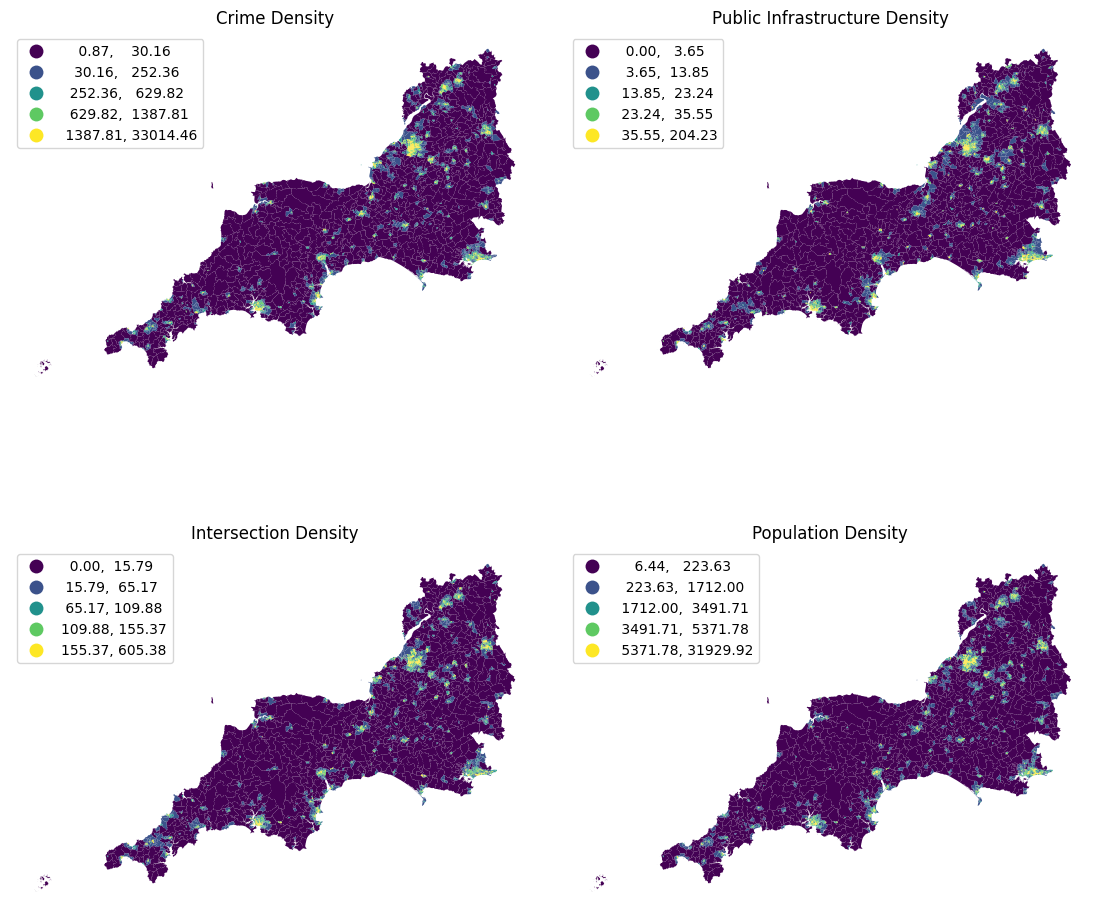

In [171]:
import matplotlib.pylab as pl
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 13))

frame_gs = gridspec.GridSpec(2,2,
                             figure=fig,
                             height_ratios=[1, 1],
                             hspace=0.06,
                             wspace=0.05
                             )

legend_kwds = {
    "loc": "upper left",
    "fontsize": 6,
    "title_fontsize": 8,
    "frameon": True
}

ax1 = fig.add_subplot(frame_gs[0, 0])
lsoa_density2.plot(
    column="crime_density",
    cmap="viridis",
    scheme="quantiles",
    k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax1
)
ax1.set_title("Crime Density", fontsize = 12)
ax1.set_axis_off()

ax2 = fig.add_subplot(frame_gs[0, 1])
lsoa_density2.plot(
    column="public_infrastructure_density",
    cmap="viridis",
    scheme="quantiles",
    k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax2
)
ax2.set_title("Public Infrastructure Density", fontsize = 12)
ax2.set_axis_off()

ax3 = fig.add_subplot(frame_gs[1, 0])
lsoa_density2.plot(
    column="intersection_density",
    cmap="viridis",
    scheme="quantiles",
    k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax3
)
ax3.set_title("Intersection Density", fontsize = 12)
ax3.set_axis_off()

ax4 = fig.add_subplot(frame_gs[1, 1])
lsoa_density2.plot(
    column="pop_density",
    cmap="viridis",
    scheme="quantiles",
    k=5,
    legend=True,
    legend_kwds={
        "loc": "upper left"},
    edgecolor="none",
    ax=ax4
)

ax4.set_title("Population Density", fontsize = 12)
ax4.set_axis_off()

In [174]:
save_fig(fig, "crime_public-infra_intersection_pop_density")

Figure saved to: Figures\crime_public-infra_intersection_pop_density.png
